# Pass 19

## Problem Definition


Business problem: estimate a house’s sale price.

Data science problem: supervised regression, since we know the real prices and the target is a number.

## Data Collection/Sources


In [1]:
#import from IPython.display import Image
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns

from sklearn import datasets, metrics, model_selection
from sklearn import model_selection
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import cross_val_score
import statsmodels.api as sm
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from scipy import stats
from scipy import special
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import f_regression

In [2]:
# file name
url = 'https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv'

In [3]:
#load all the data
house_df= pd.read_csv(url)


In [4]:
# find all text columns (object)
obj_columns = house_df.select_dtypes(include=['object']).columns.tolist()
obj_columns

['MS Zoning',
 'Street',
 'Alley',
 'Lot Shape',
 'Land Contour',
 'Utilities',
 'Lot Config',
 'Land Slope',
 'Neighborhood',
 'Condition 1',
 'Condition 2',
 'Bldg Type',
 'House Style',
 'Roof Style',
 'Roof Matl',
 'Exterior 1st',
 'Exterior 2nd',
 'Mas Vnr Type',
 'Exter Qual',
 'Exter Cond',
 'Foundation',
 'Bsmt Qual',
 'Bsmt Cond',
 'Bsmt Exposure',
 'BsmtFin Type 1',
 'BsmtFin Type 2',
 'Heating',
 'Heating QC',
 'Central Air',
 'Electrical',
 'Kitchen Qual',
 'Functional',
 'Fireplace Qu',
 'Garage Type',
 'Garage Finish',
 'Garage Qual',
 'Garage Cond',
 'Paved Drive',
 'Pool QC',
 'Fence',
 'Misc Feature',
 'Sale Type',
 'Sale Condition']

In [5]:
# Keep ALL columns, but drop the ID columns (labels, not measurements)
house_df_all = house_df.drop(columns=['Order', 'PID'], errors='ignore').copy()

# list of number columns (includes SalePrice)
num_columns = house_df_all.select_dtypes(include=['int64', 'float64']).columns.tolist()
num_columns

['MS SubClass',
 'Lot Frontage',
 'Lot Area',
 'Overall Qual',
 'Overall Cond',
 'Year Built',
 'Year Remod/Add',
 'Mas Vnr Area',
 'BsmtFin SF 1',
 'BsmtFin SF 2',
 'Bsmt Unf SF',
 'Total Bsmt SF',
 '1st Flr SF',
 '2nd Flr SF',
 'Low Qual Fin SF',
 'Gr Liv Area',
 'Bsmt Full Bath',
 'Bsmt Half Bath',
 'Full Bath',
 'Half Bath',
 'Bedroom AbvGr',
 'Kitchen AbvGr',
 'TotRms AbvGrd',
 'Fireplaces',
 'Garage Yr Blt',
 'Garage Cars',
 'Garage Area',
 'Wood Deck SF',
 'Open Porch SF',
 'Enclosed Porch',
 '3Ssn Porch',
 'Screen Porch',
 'Pool Area',
 'Misc Val',
 'Mo Sold',
 'Yr Sold',
 'SalePrice']

In [6]:
# Columns data types
house_df_all.dtypes.sort_values()


,0
MS SubClass,int64
Low Qual Fin SF,int64
Gr Liv Area,int64
Full Bath,int64
Half Bath,int64
...,...
Condition 1,object
Kitchen Qual,object
Neighborhood,object
Land Slope,object


In [7]:
# look at first and last few rows
house_df_all.head()


,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,20,RL,62.0,14299,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,MnPrv,NaN,0,7,2007,WD,Normal,115400
1,90,RL,72.0,10791,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,NaN,Shed,500,10,2006,WD,Normal,90000
2,50,RM,50.0,9000,Pave,NaN,Reg,Bnk,AllPub,Inside,...,0,NaN,NaN,NaN,0,12,2007,WD,Normal,141000
3,60,FV,68.0,7379,Pave,NaN,IR1,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,254000
4,70,RL,60.0,7200,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,MnPrv,NaN,0,4,2009,WD,Normal,155000


In [8]:
# look at the last few rows
house_df_all.tail()

,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
2632,50,RM,52.0,6240,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,MnPrv,Shed,400,9,2006,WD,Normal,114500
2633,80,RL,74.0,10778,Pave,NaN,IR1,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,7,2009,WD,Normal,162000
2634,120,RL,61.0,3782,Pave,NaN,IR1,Lvl,AllPub,CulDSac,...,0,NaN,NaN,NaN,0,9,2009,WD,Normal,211500
2635,20,RL,78.0,10140,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,MnPrv,NaN,0,8,2009,WD,Normal,165000
2636,60,RL,41.0,12460,Pave,NaN,IR1,Lvl,AllPub,FR2,...,0,NaN,NaN,NaN,0,5,2008,WD,Normal,225000


In [9]:
# look at shape and size

print(house_df_all.shape)
print(house_df_all.size)


(2637, 80)
210960


In [10]:
# display meta data (info)
house_df_all.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2637 entries, 0 to 2636
Data columns (total 80 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   MS SubClass      2637 non-null   int64  
 1   MS Zoning        2637 non-null   object 
 2   Lot Frontage     2188 non-null   float64
 3   Lot Area         2637 non-null   int64  
 4   Street           2637 non-null   object 
 5   Alley            180 non-null    object 
 6   Lot Shape        2637 non-null   object 
 7   Land Contour     2637 non-null   object 
 8   Utilities        2637 non-null   object 
 9   Lot Config       2637 non-null   object 
 10  Land Slope       2637 non-null   object 
 11  Neighborhood     2637 non-null   object 
 12  Condition 1      2637 non-null   object 
 13  Condition 2      2637 non-null   object 
 14  Bldg Type        2637 non-null   object 
 15  House Style      2637 non-null   object 
 16  Overall Qual     2637 non-null   int64  
 17  Overall Cond  

In [11]:
# summary statistics: numbers first, then text
display(house_df_all.describe())
display(house_df_all.describe(include='object'))



,MS SubClass,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,...,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold,SalePrice
count,2637.000000,2188.000000,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000,2614.000000,2636.000000,2636.000000,...,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000
mean,57.349261,69.166819,10044.694729,6.097459,5.569966,1971.288586,1984.202882,101.887911,438.441199,51.068665,...,94.305271,46.984452,22.813424,2.368601,15.775123,2.130072,42.014031,6.243838,2007.795601,179986.230186
std,42.499091,23.356779,6742.549521,1.411522,1.118262,30.306986,20.913077,179.578232,449.602326,172.521803,...,126.927272,66.564333,61.177638,23.160600,55.783751,35.140140,393.158781,2.722093,1.306403,78309.251522
min,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,12789.000000
25%,20.000000,58.000000,7436.000000,5.000000,5.000000,1954.000000,1965.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000,2007.000000,129500.000000
50%,50.000000,68.000000,9450.000000,6.000000,5.000000,1973.000000,1993.000000,0.000000,368.000000,0.000000,...,0.000000,27.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,160000.000000
75%,70.000000,80.000000,11526.000000,7.000000,6.000000,2001.000000,2004.000000,164.000000,732.000000,0.000000,...,168.000000,70.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,213000.000000
max,190.000000,313.000000,164660.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,1526.000000,...,1424.000000,742.000000,584.000000,407.000000,576.000000,800.000000,12500.000000,12.000000,2010.000000,745000.000000


,MS Zoning,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,...,Garage Type,Garage Finish,Garage Qual,Garage Cond,Paved Drive,Pool QC,Fence,Misc Feature,Sale Type,Sale Condition
count,2637,2637,180,2637,2637,2637,2637,2637,2637,2637,...,2492,2490,2490,2490,2637,11,528,96,2637,2637
unique,7,2,2,4,4,3,5,3,28,9,...,6,3,5,5,3,4,4,4,10,6
top,RL,Pave,Grvl,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Norm,...,Attchd,Unf,TA,TA,Y,Gd,MnPrv,Shed,WD,Normal
freq,2043,2625,111,1662,2365,2634,1924,2511,397,2273,...,1563,1106,2356,2400,2395,4,306,87,2286,2166


In [12]:
# look for how the often a value appears
house_df['SalePrice'].value_counts(dropna=False)


,count
SalePrice,
140000,31
135000,30
130000,28
155000,24
160000,22
...,...
160200,1
174190,1
415298,1


In [13]:
# look for nulls in target and features
house_df_all.isnull().sum().sort_values(ascending=False)

,0
Pool QC,2626
Misc Feature,2541
Alley,2457
Fence,2109
Mas Vnr Type,1607
...,...
Mo Sold,0
Yr Sold,0
Sale Type,0
Sale Condition,0


## Data Cleaning


### Backup 1

In [14]:
# make backup
house_df_all_backup = house_df_all.copy()

In [15]:
# restore from backup
house_df_all = house_df_all_backup.copy()

### Address any rows with nulls

- If the number of nulls in a column is low, it would be easiest to drop the row.
- If the number of nulls in a column is high, it would be easiest to drop the column.
- If the number of nulls in a column is between the low and high, one should impute values for the nulls.

In [16]:
# look for nulls in feature in percentage
house_df_all.isnull().mean() * 100

,0
MS SubClass,0.000000
MS Zoning,0.000000
Lot Frontage,17.026925
Lot Area,0.000000
Street,0.000000
...,...
Mo Sold,0.000000
Yr Sold,0.000000
Sale Type,0.000000
Sale Condition,0.000000


### Impute

In [17]:
# 1. Number columns: fill with the median (same as Pass 13)
median_frontage = house_df_all['Lot Frontage'].median()
median_garage_yr = house_df_all['Garage Yr Blt'].median()
house_df_all['Lot Frontage'] = house_df_all['Lot Frontage'].fillna(median_frontage)
house_df_all['Garage Yr Blt'] = house_df_all['Garage Yr Blt'].fillna(median_garage_yr)

# 2. Number columns with only a few nulls: drop those rows (same as Pass 13)
house_df_all = house_df_all.dropna(subset=['Mas Vnr Area', 'BsmtFin SF 1', 'BsmtFin SF 2',
                                           'Bsmt Unf SF', 'Total Bsmt SF', 'Bsmt Full Bath',
                                           'Bsmt Half Bath', 'Garage Cars', 'Garage Area'])

# 3. Text columns: null means "doesn't have it", so fill with 'None'
house_df_all = house_df_all.fillna('None')

house_df_all.shape


(2611, 80)

In [18]:
#check that null are removed from object
house_df_all.isnull().sum()

,0
MS SubClass,0
MS Zoning,0
Lot Frontage,0
Lot Area,0
Street,0
...,...
Mo Sold,0
Yr Sold,0
Sale Type,0
Sale Condition,0


## Exploratory Data Analysis


Linear Regression has two requirements:
1. the features are correlated with the target
1. the features are not correlated with each other

In [19]:
# How many categories does each column have?
house_df_all.nunique().sort_values()

,0
Street,2
Central Air,2
Land Slope,3
Alley,3
Bsmt Half Bath,3
...,...
Total Bsmt SF,994
1st Flr SF,1015
Bsmt Unf SF,1076
Gr Liv Area,1206


In [20]:
# Average price for each category in one feature
house_df_all.groupby('Neighborhood')['SalePrice'].mean().sort_values()

,SalePrice
Neighborhood,
MeadowV,96271.764706
IDOTRR,101245.915663
BrDale,106919.642857
OldTown,123955.233945
BrkSide,124995.052083
Edwards,126999.493976
SWISU,135271.659091
Landmrk,137000.000000
Sawyer,137046.123188


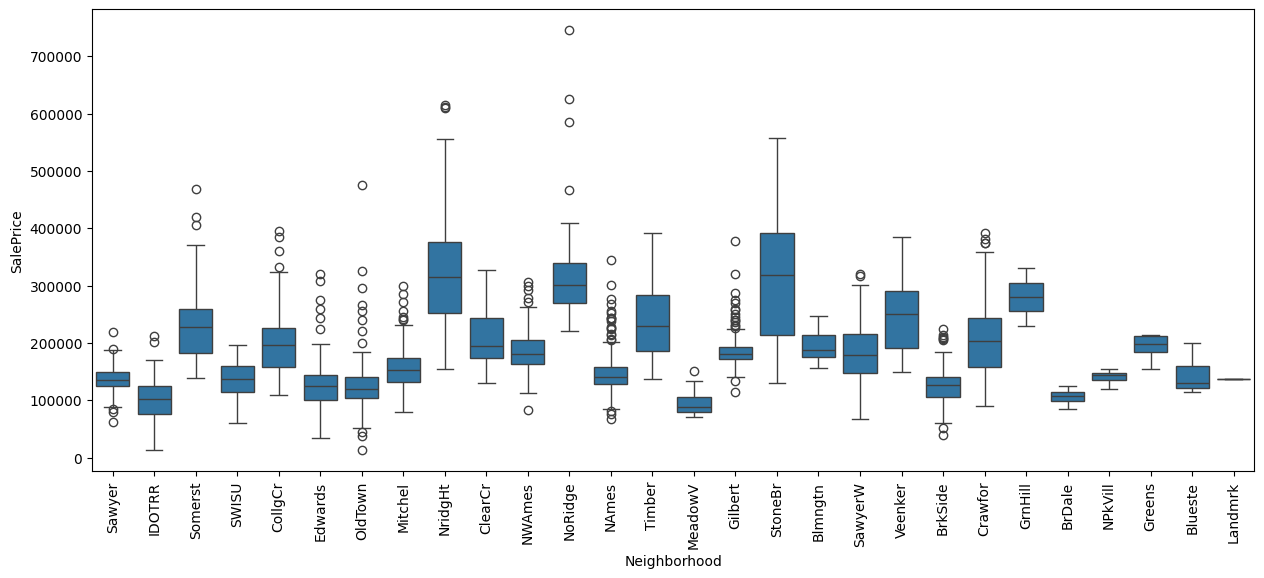

In [21]:
# Box plot: price spread for each category
# Boxes at very different heights = the feature is linked to price
# Boxes all at the same height = the feature doesn't tell you much
plt.figure(figsize=(15, 6))
sns.boxplot(data=house_df_all, x='Neighborhood', y='SalePrice')
plt.xticks(rotation=90)
plt.show()

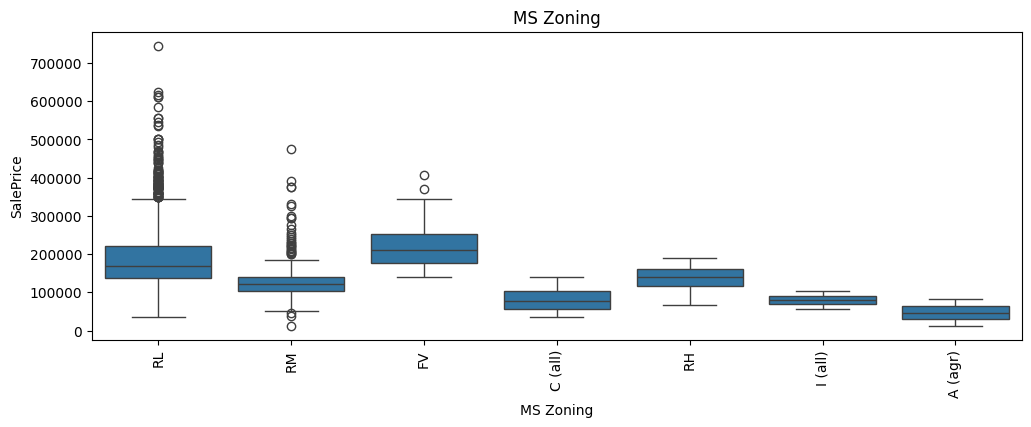

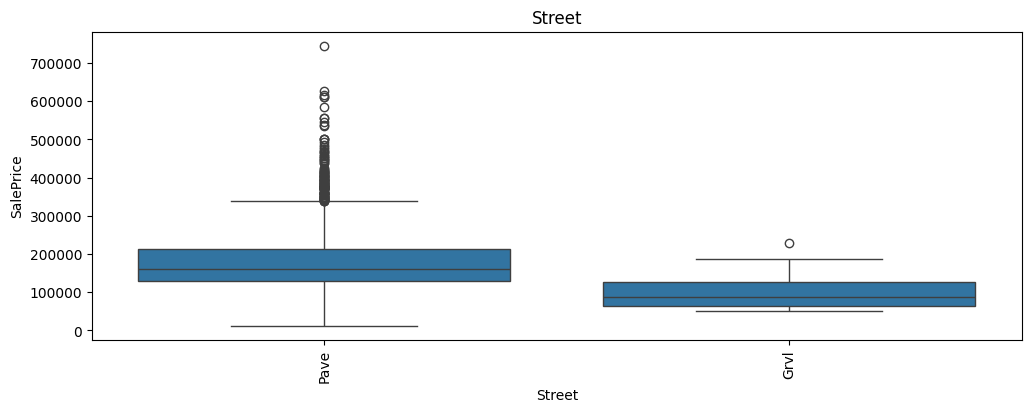

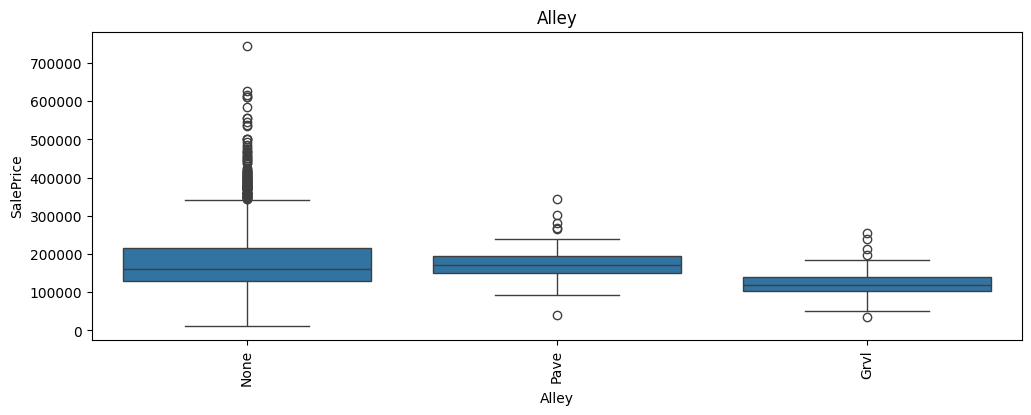

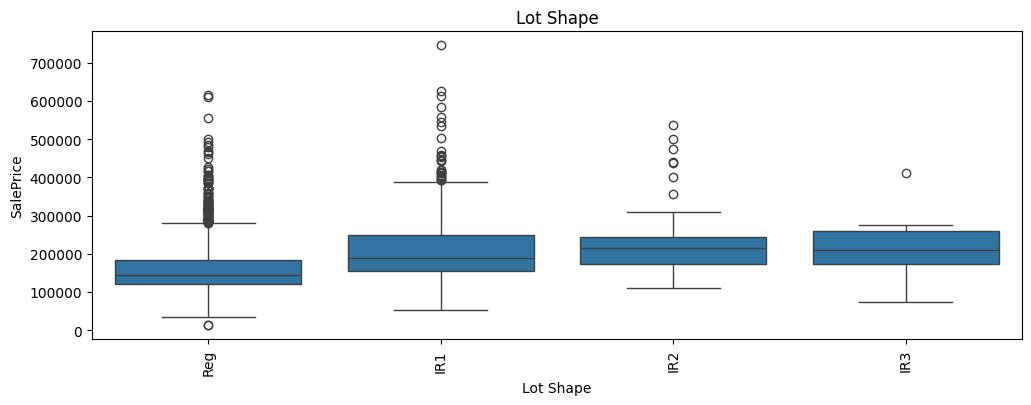

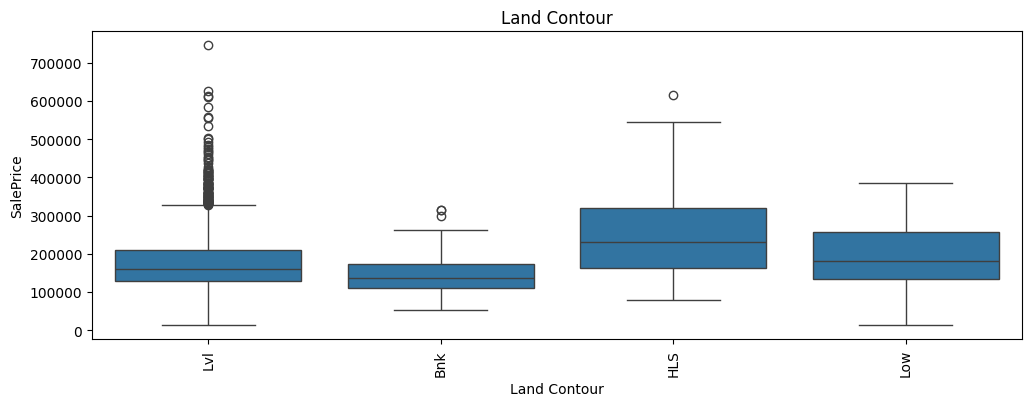

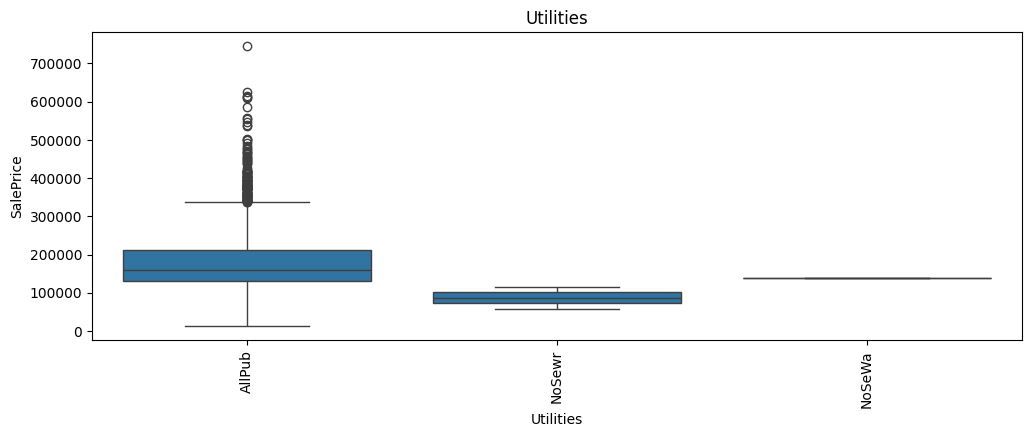

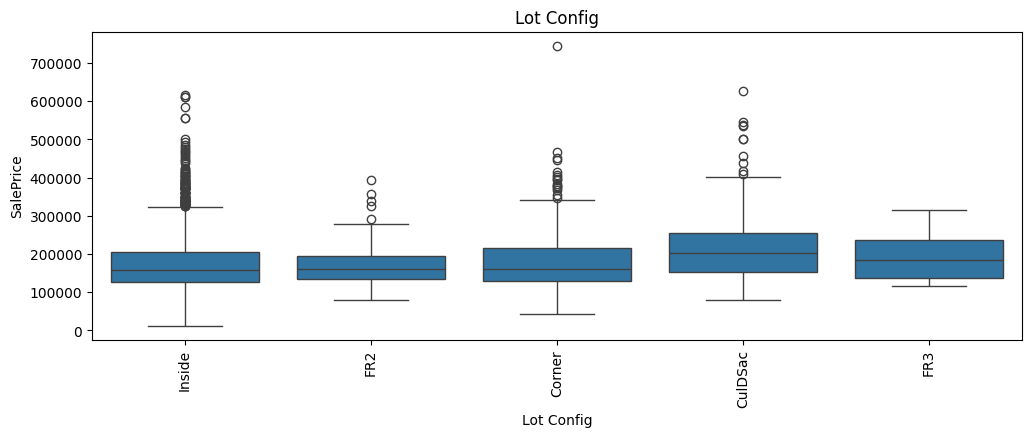

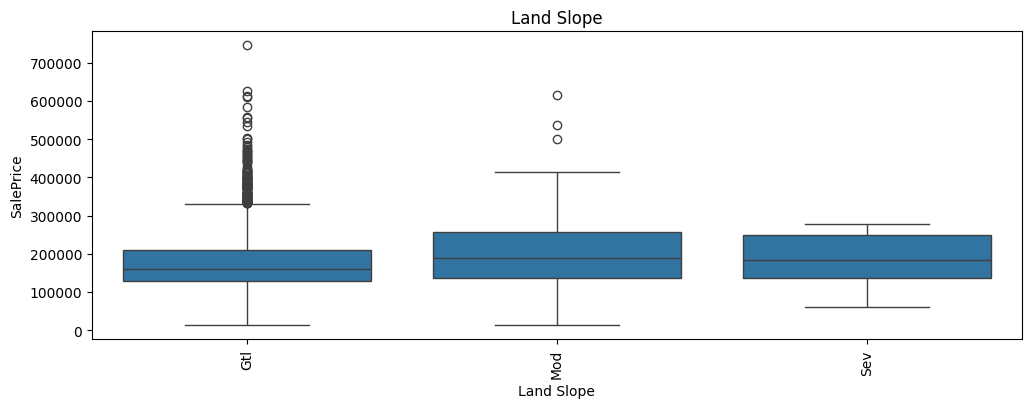

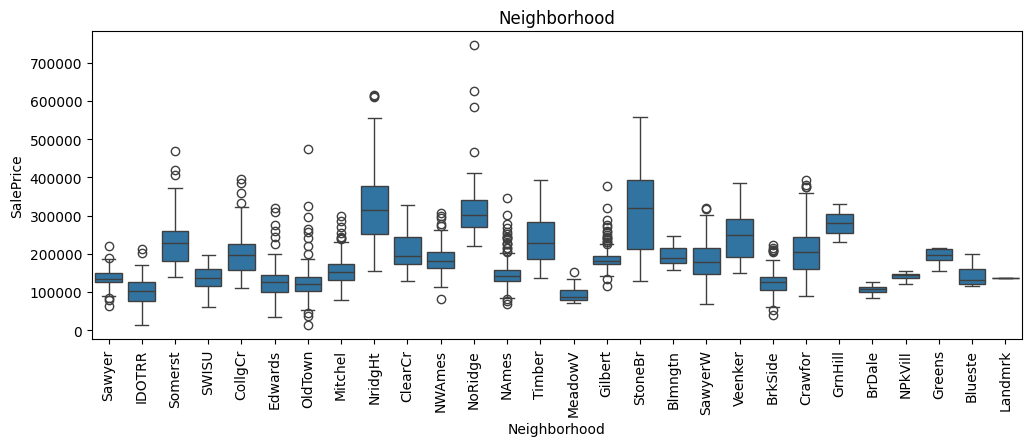

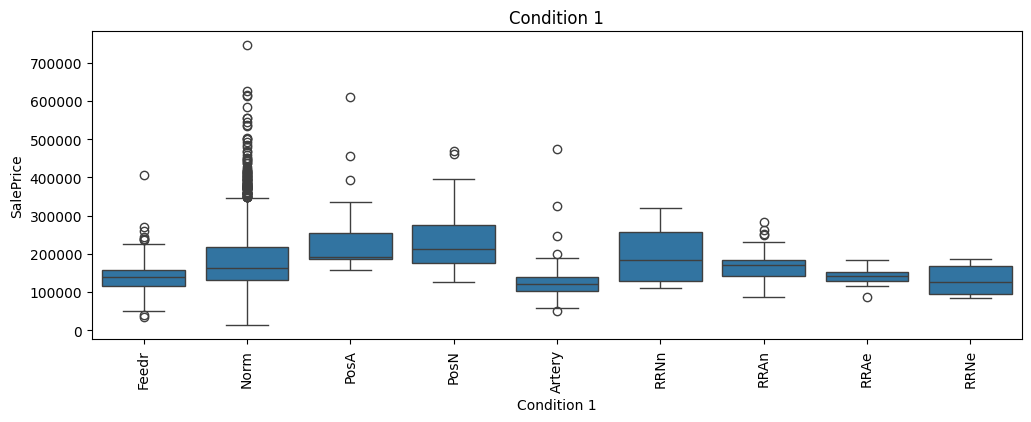

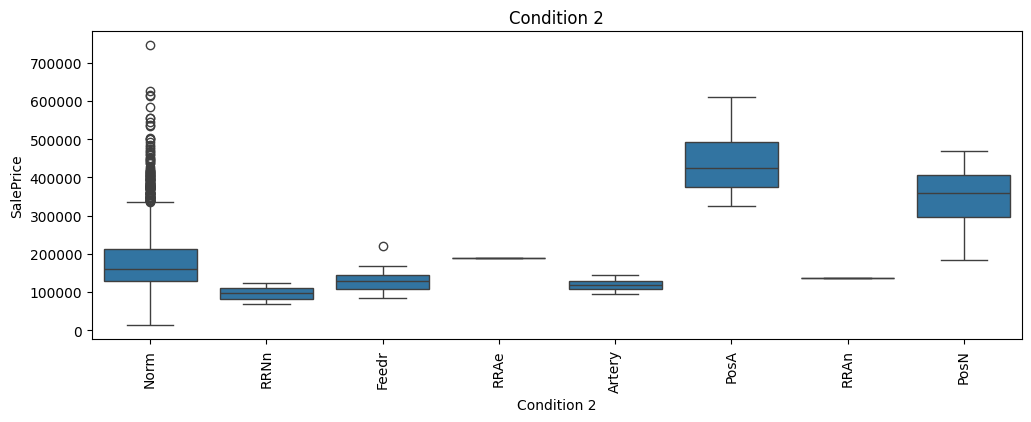

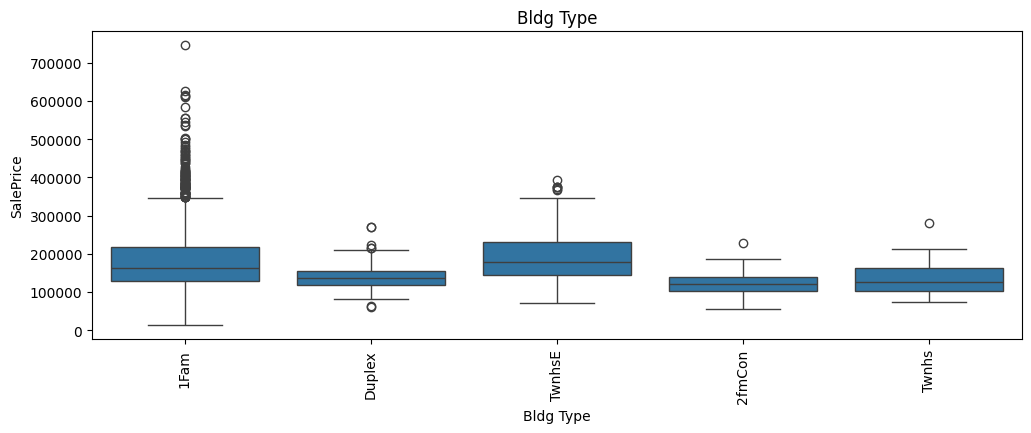

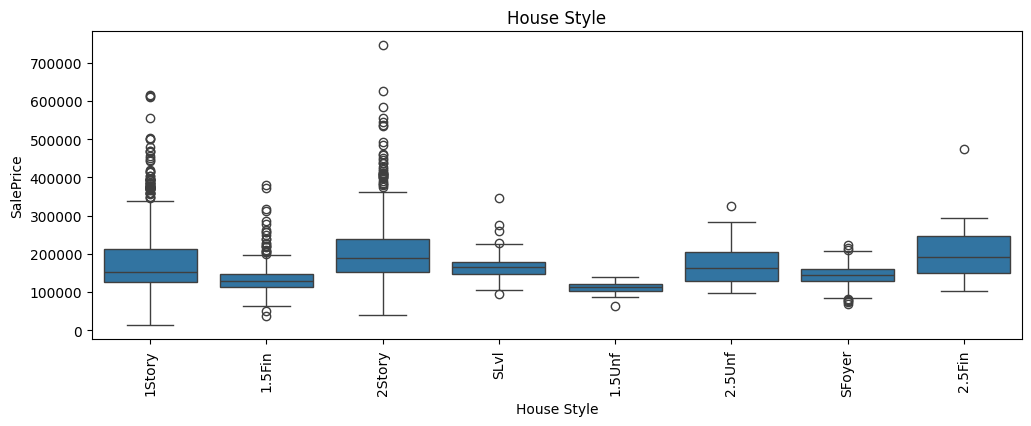

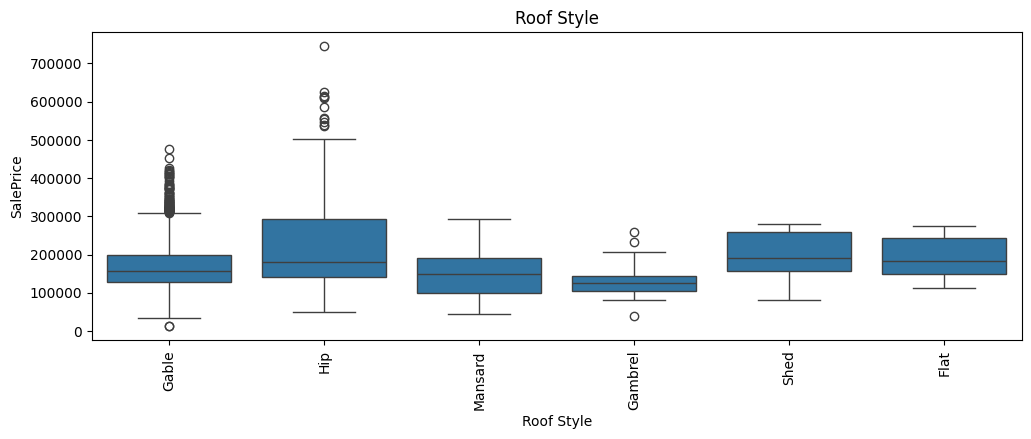

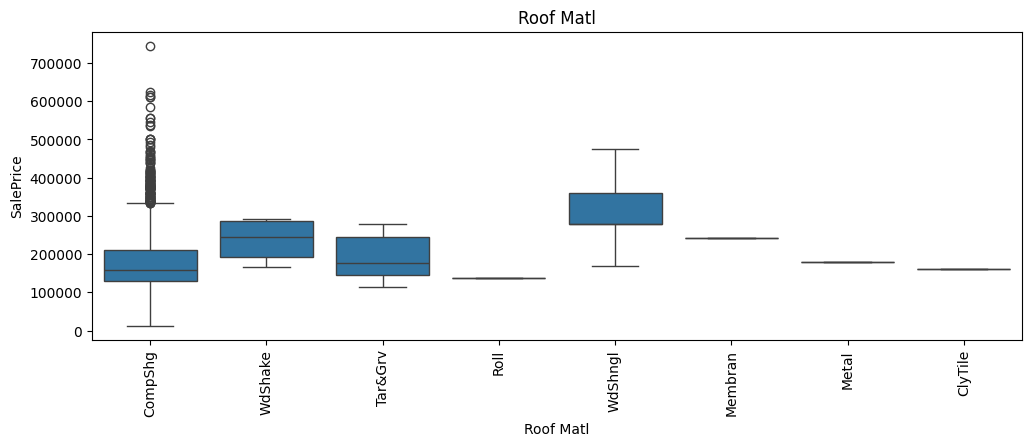

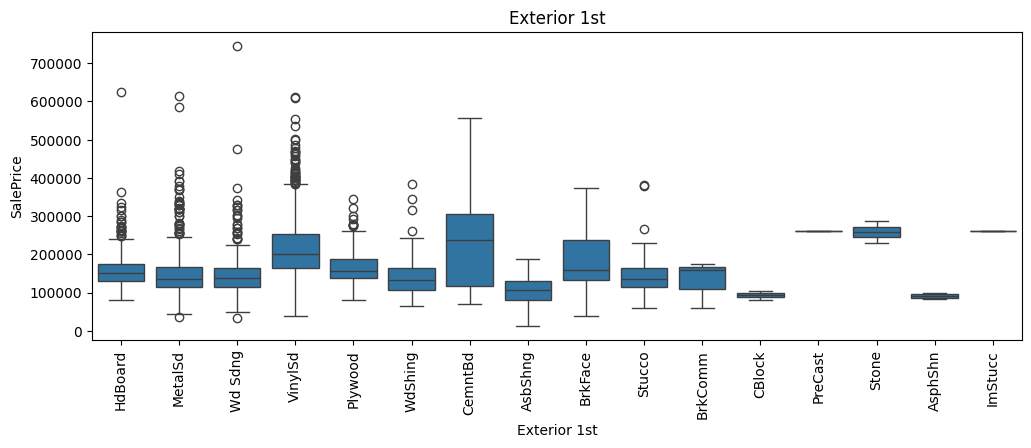

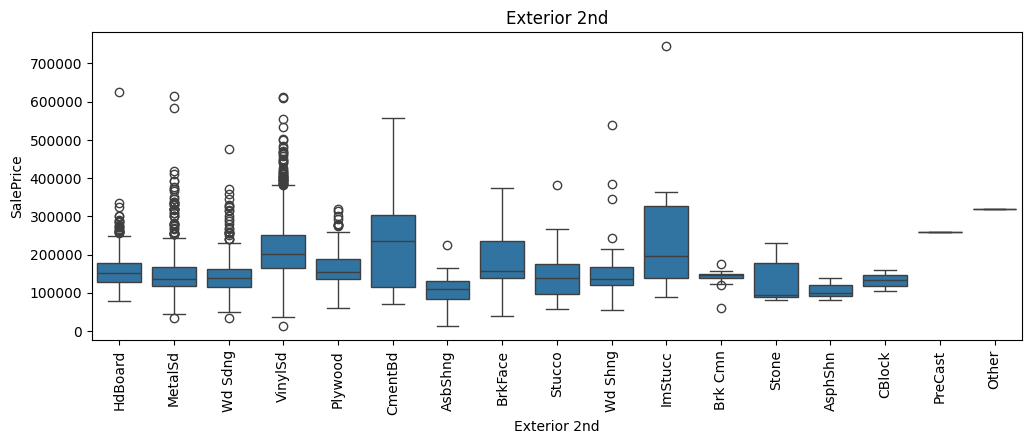

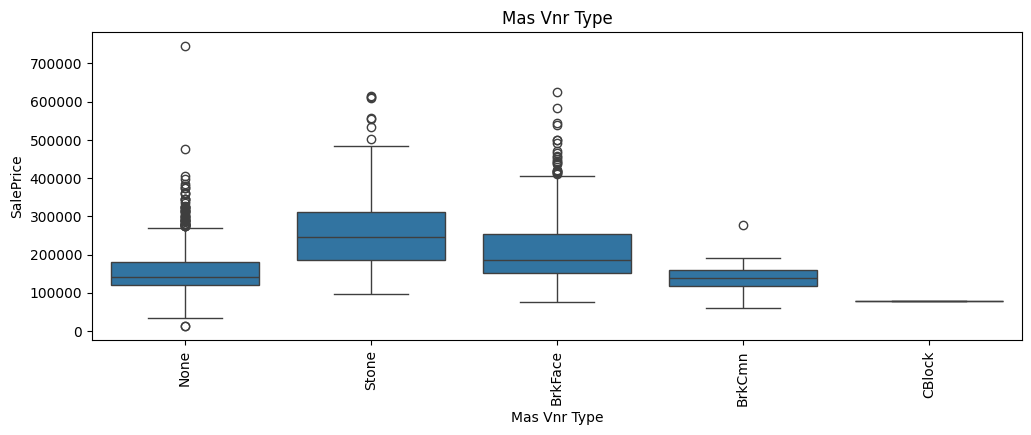

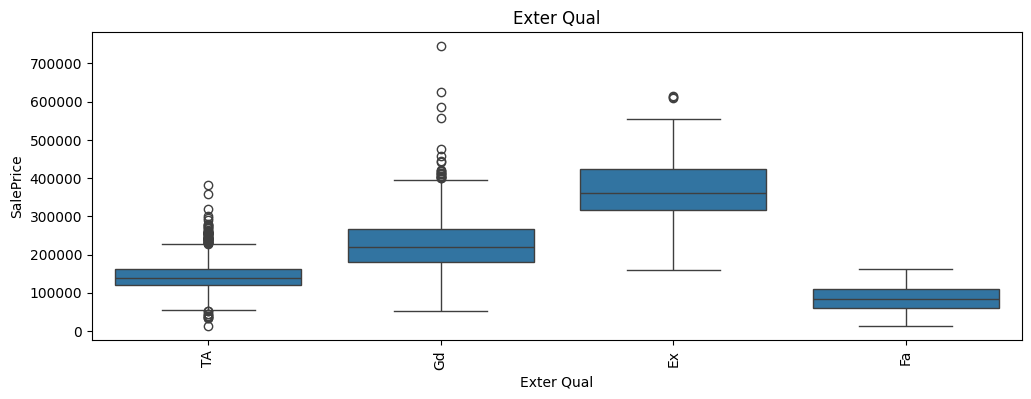

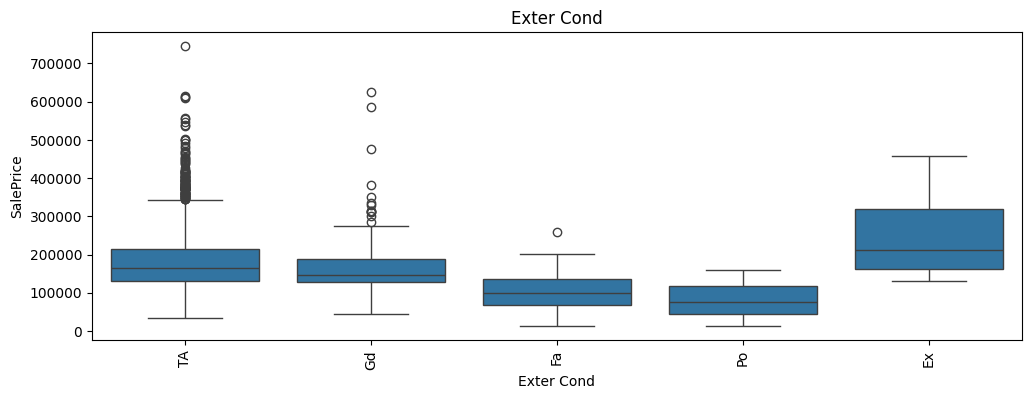

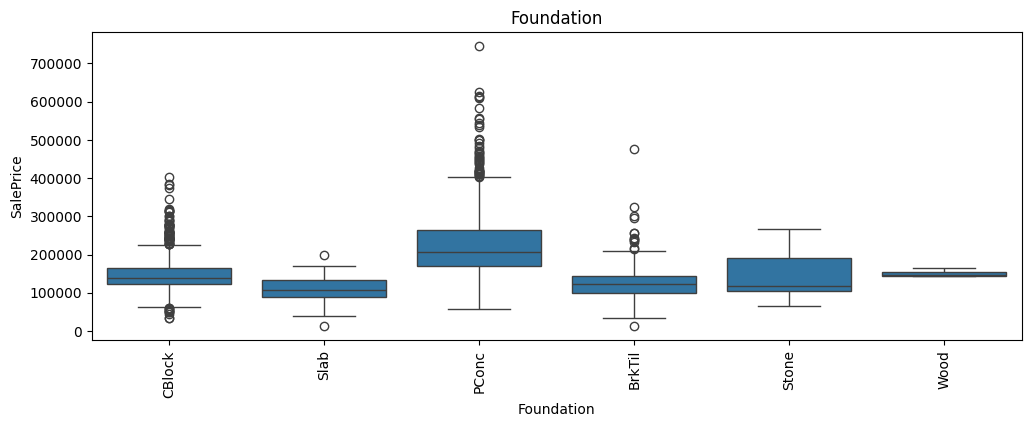

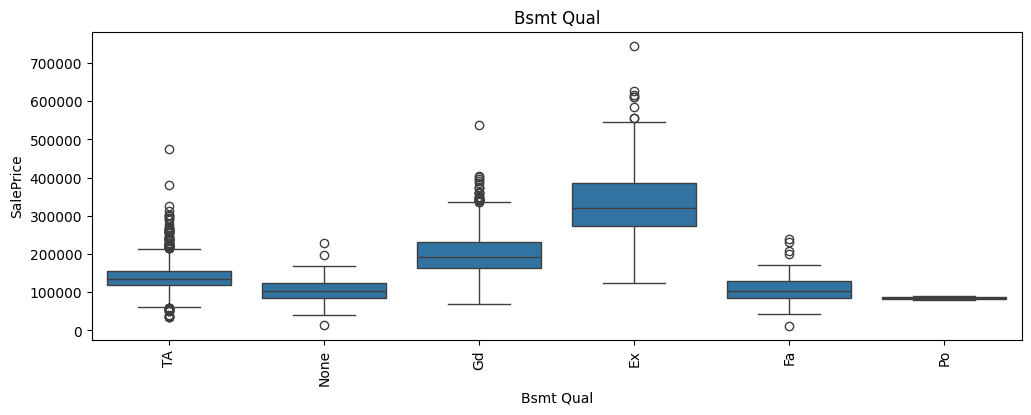

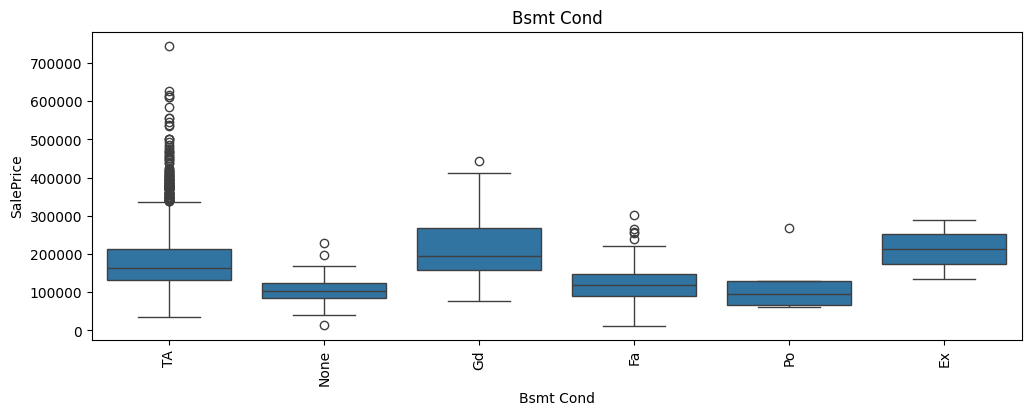

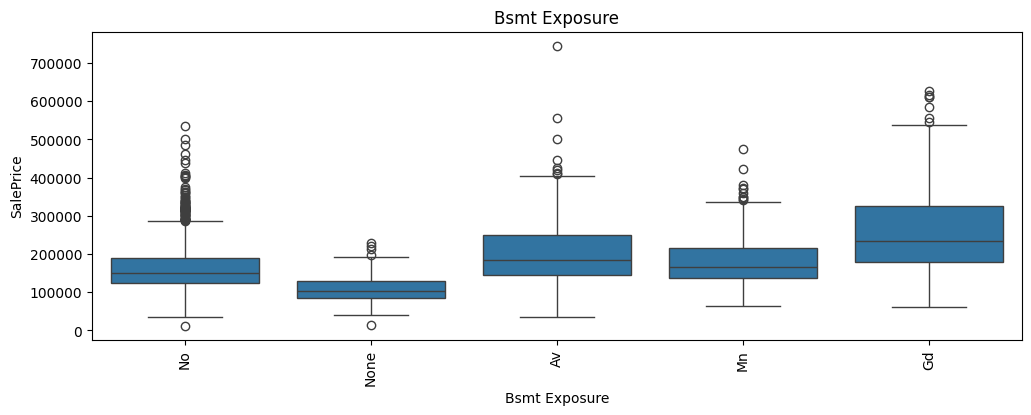

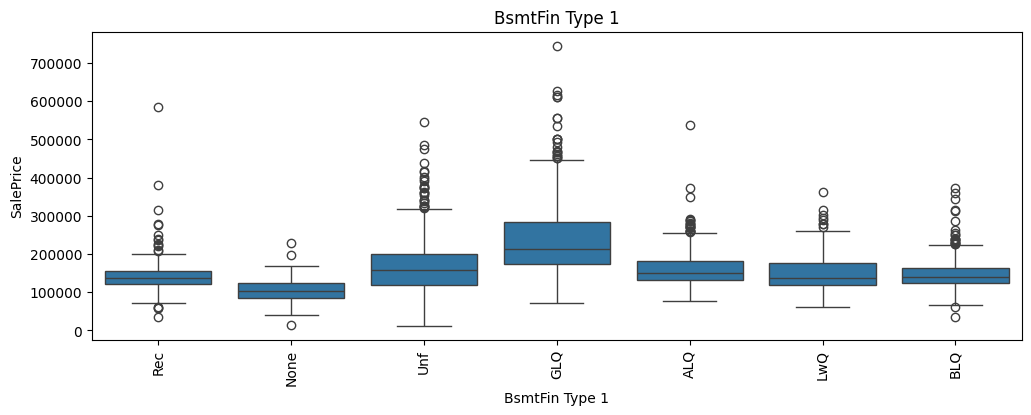

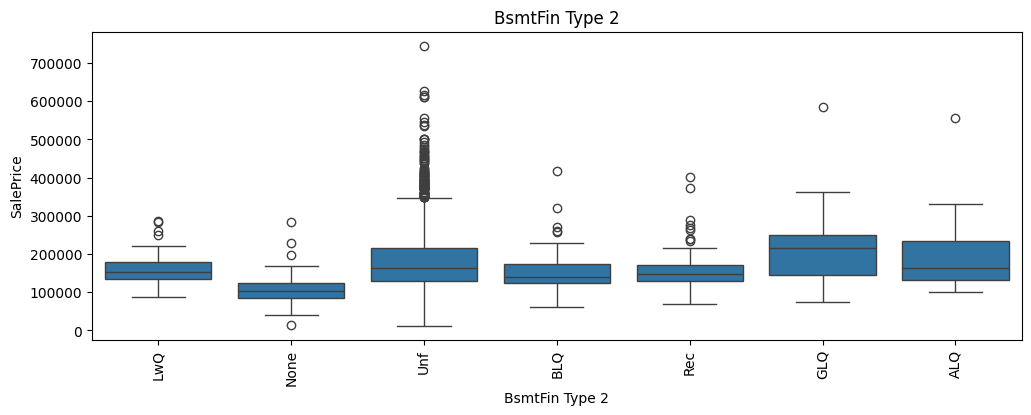

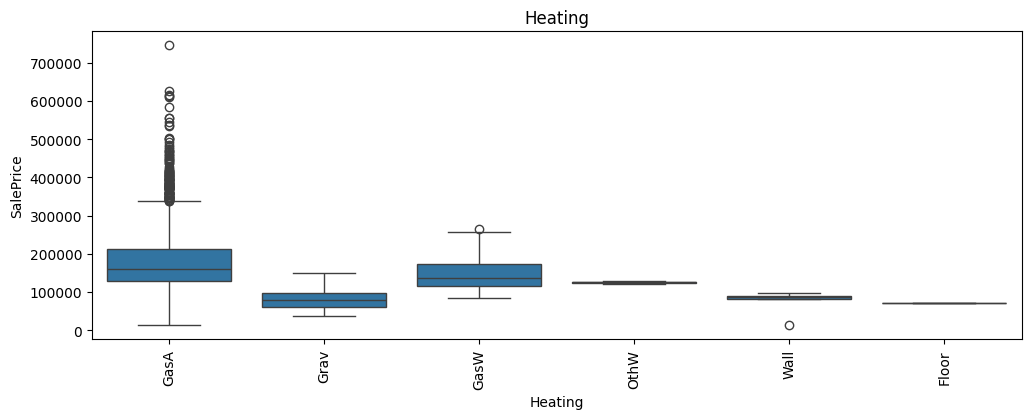

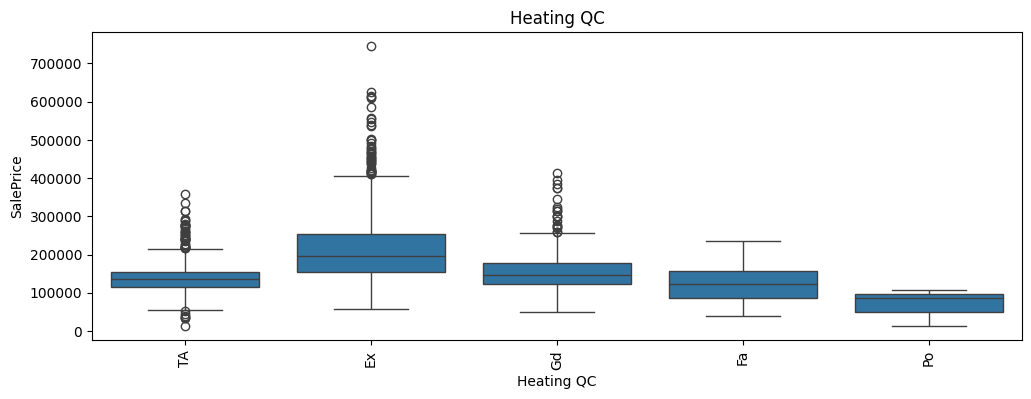

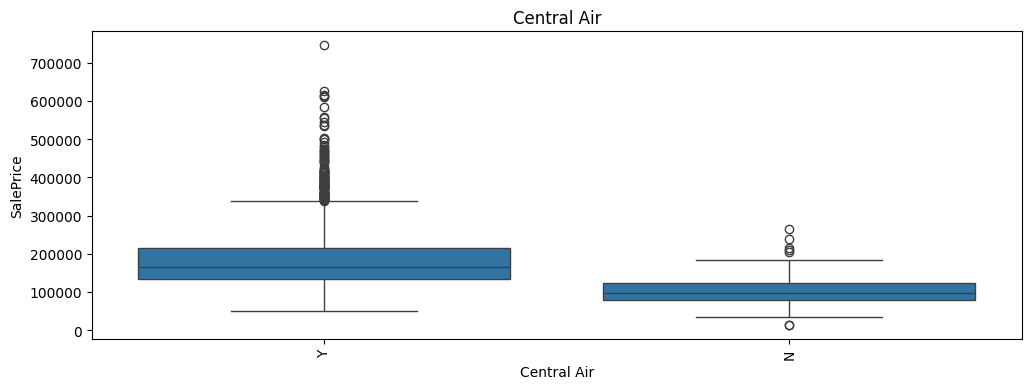

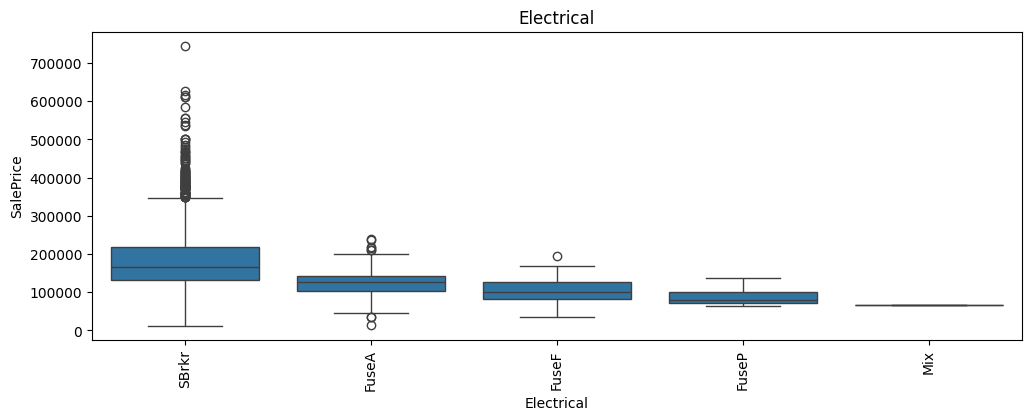

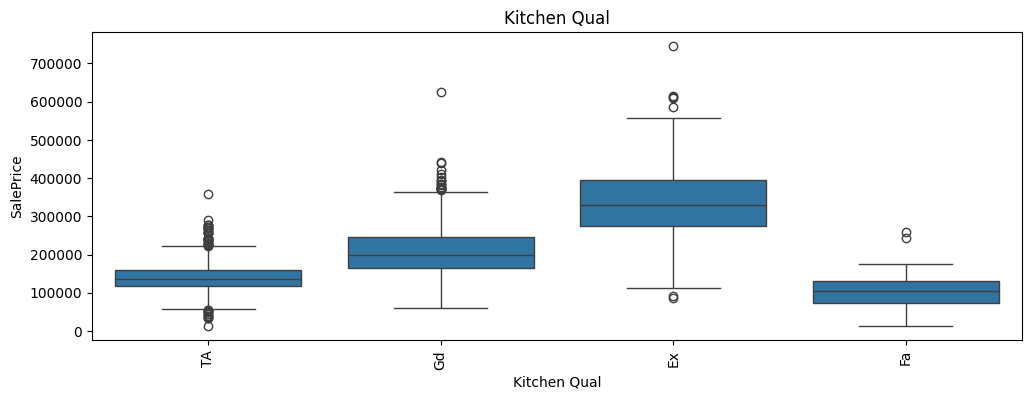

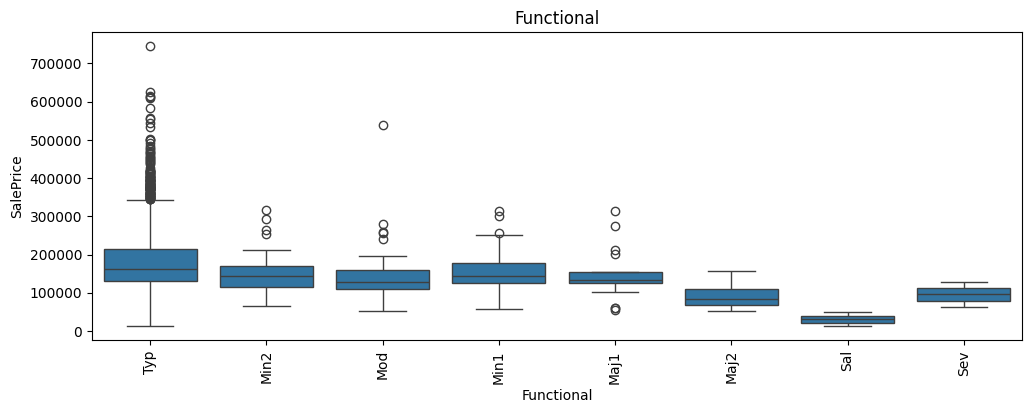

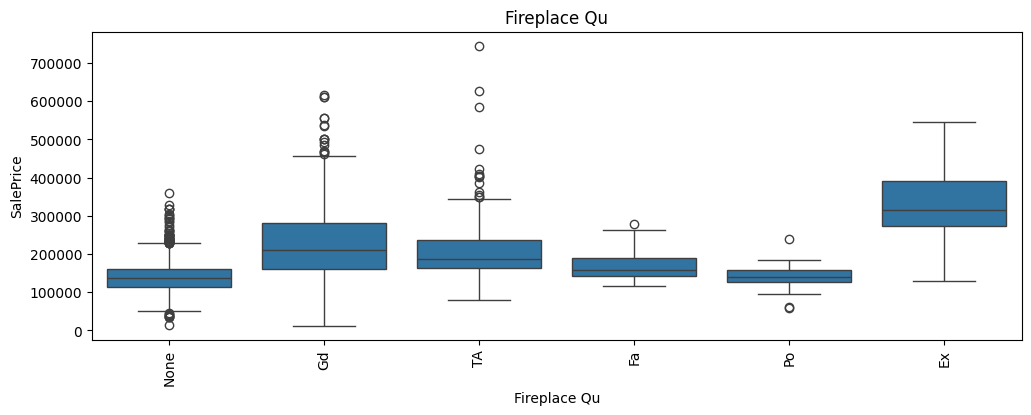

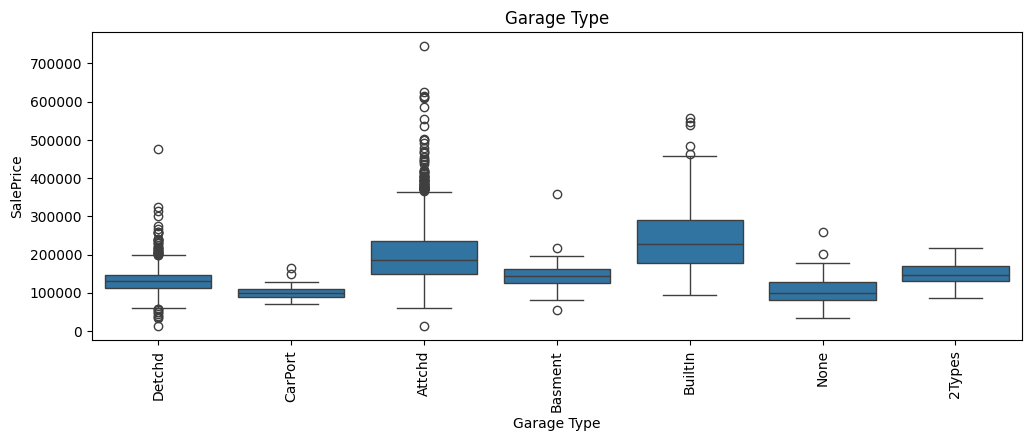

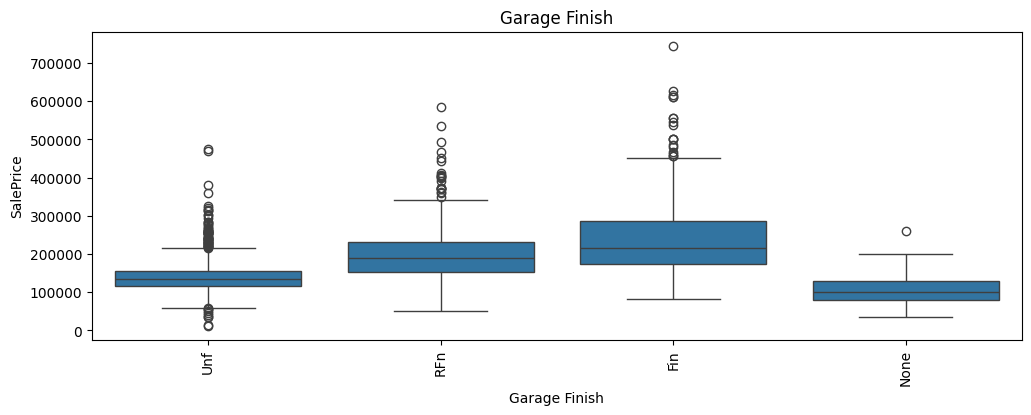

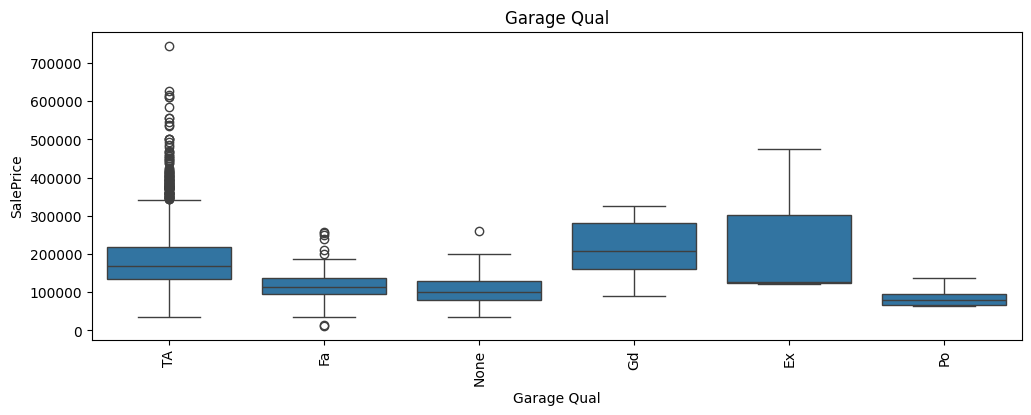

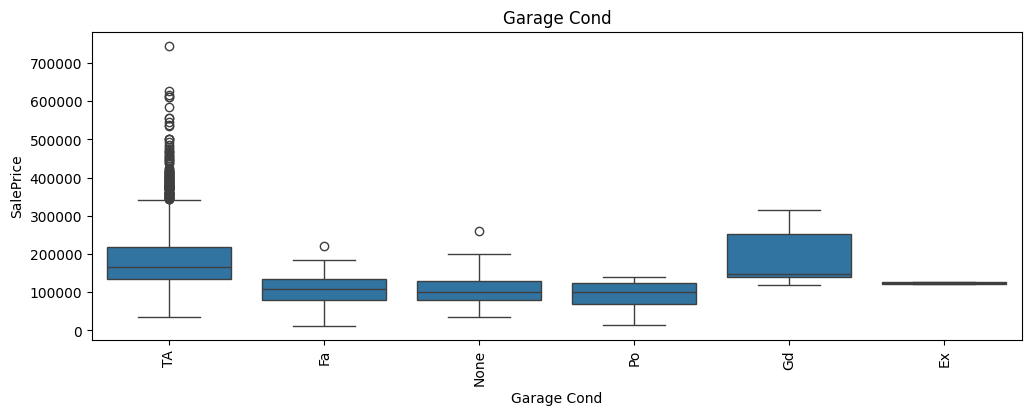

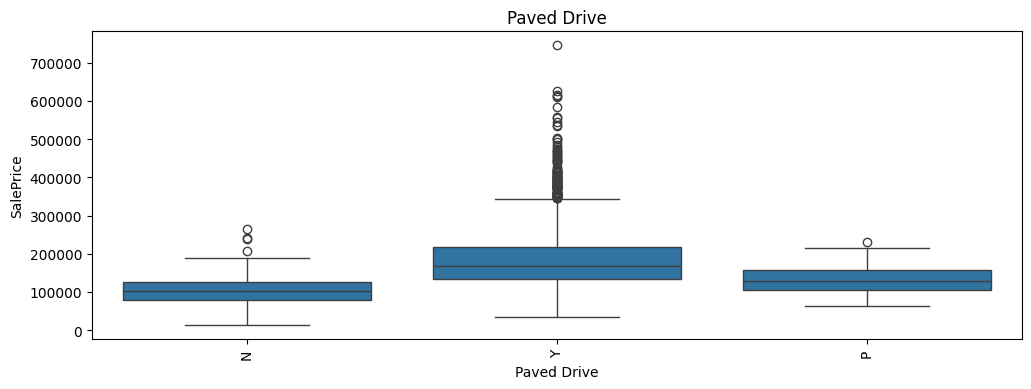

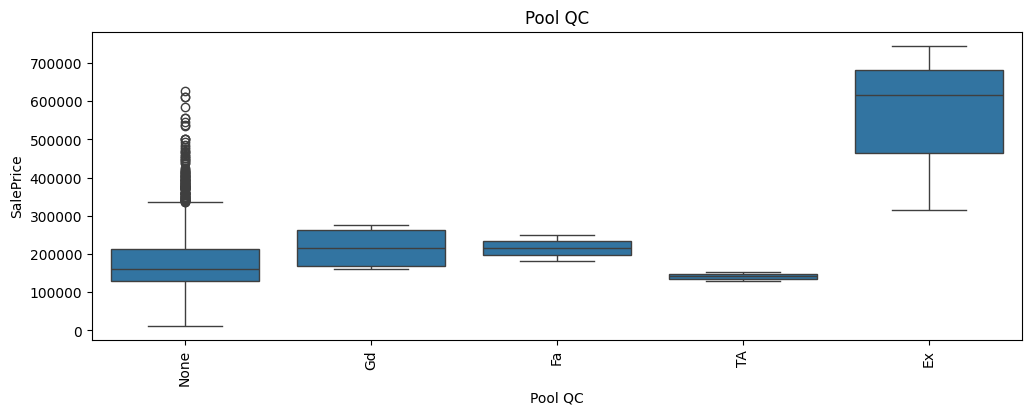

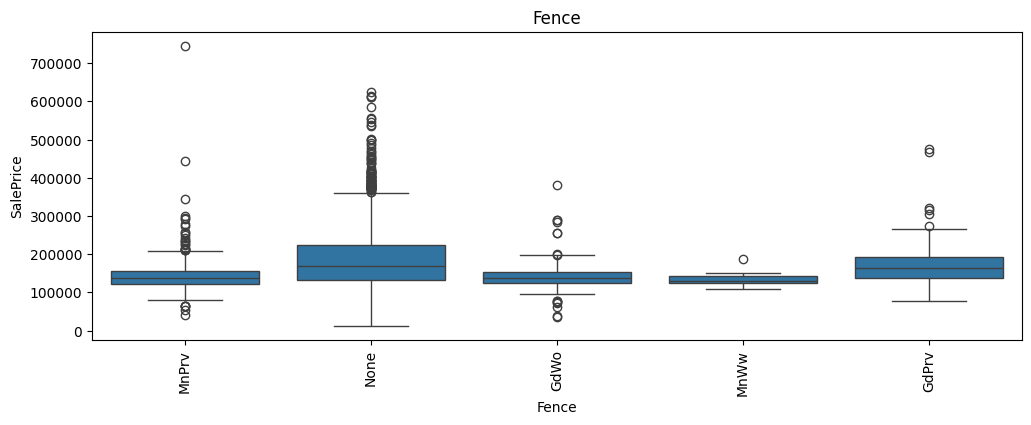

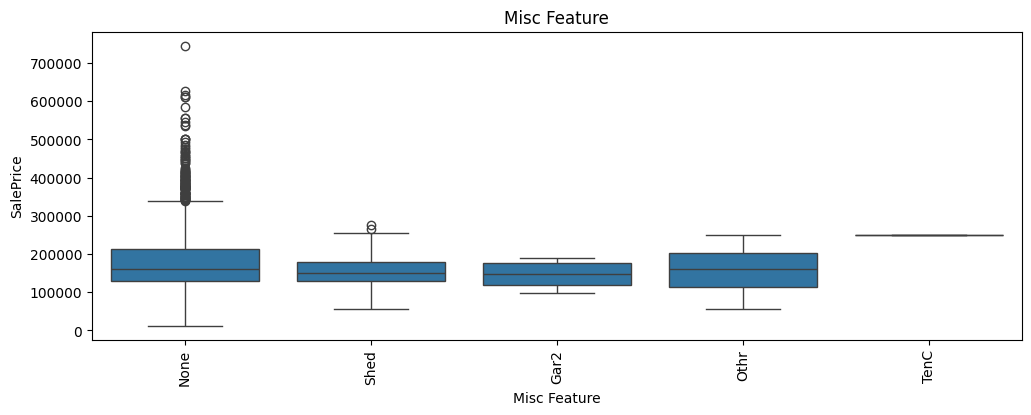

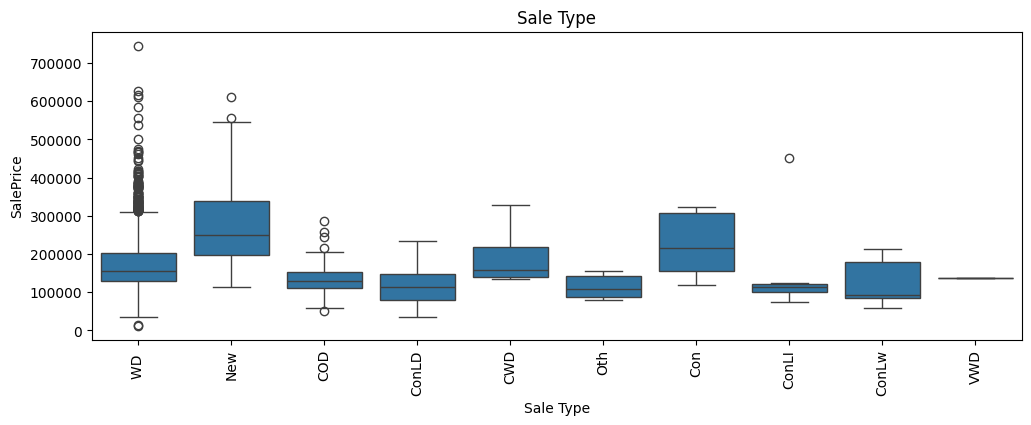

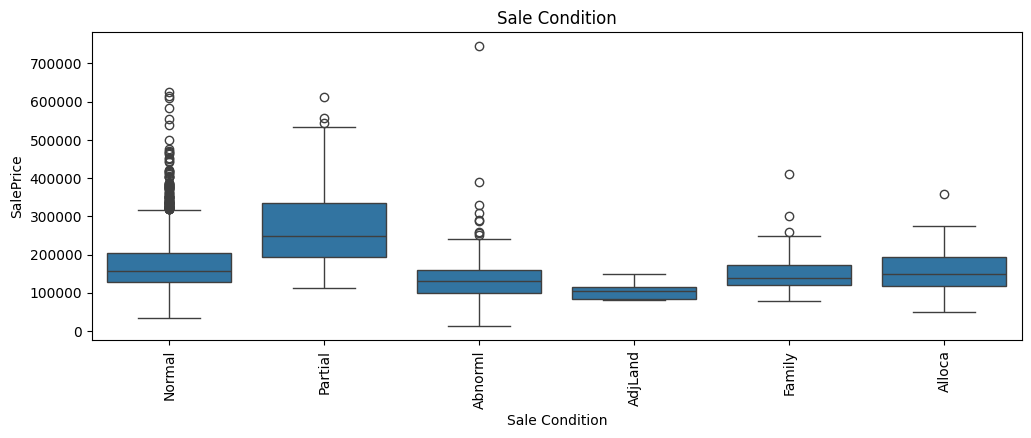

In [22]:
# Same box plot for every text feature
for col in obj_columns:
    plt.figure(figsize=(12, 4))
    sns.boxplot(data=house_df_all, x=col, y='SalePrice')
    plt.xticks(rotation=90)
    plt.title(col)
    plt.show()

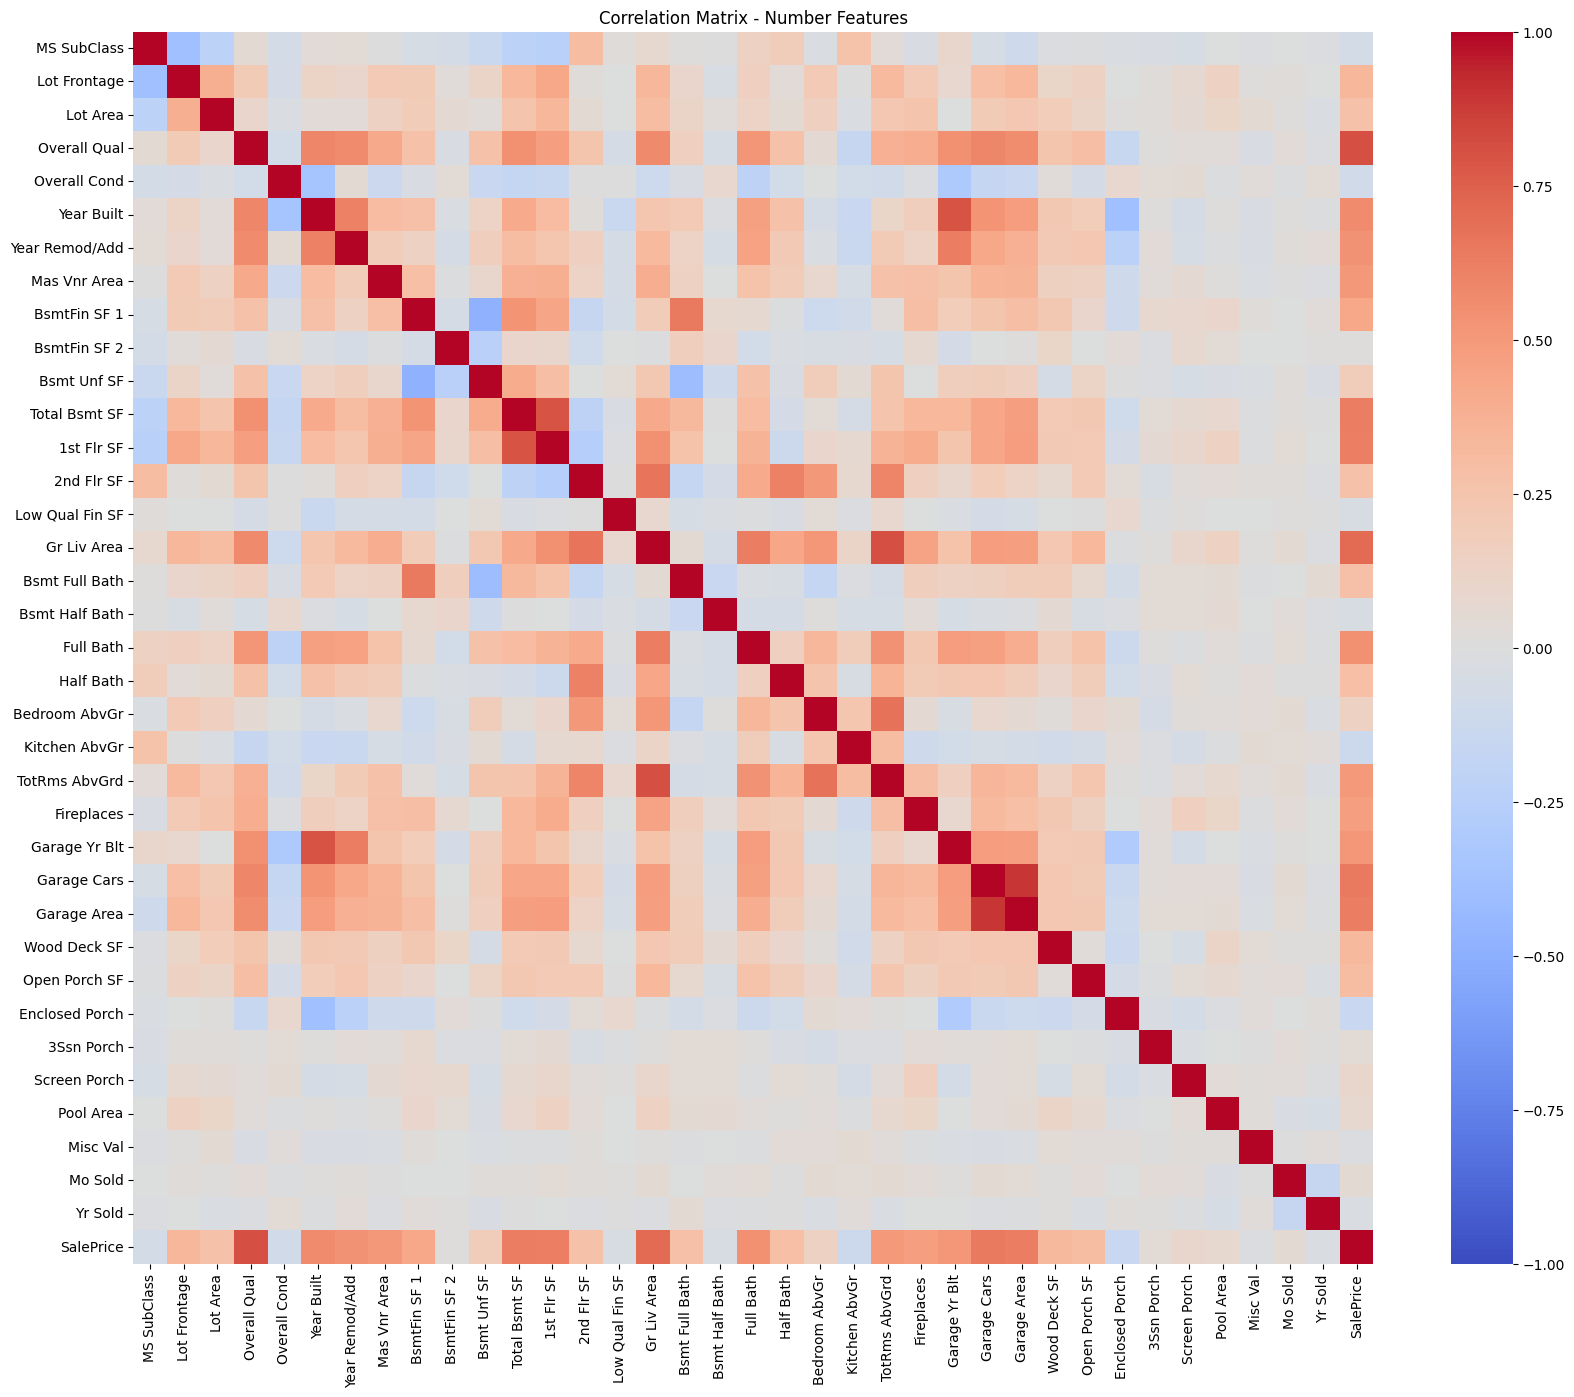

In [23]:
# Number features: correlation heatmap (text columns can't be in .corr())
plt.figure(figsize=(20, 16))
sns.heatmap(house_df_all[num_columns].corr(), annot=False,
            cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Correlation Matrix - Number Features')
plt.show()

Lambda: 0.03520881167313269


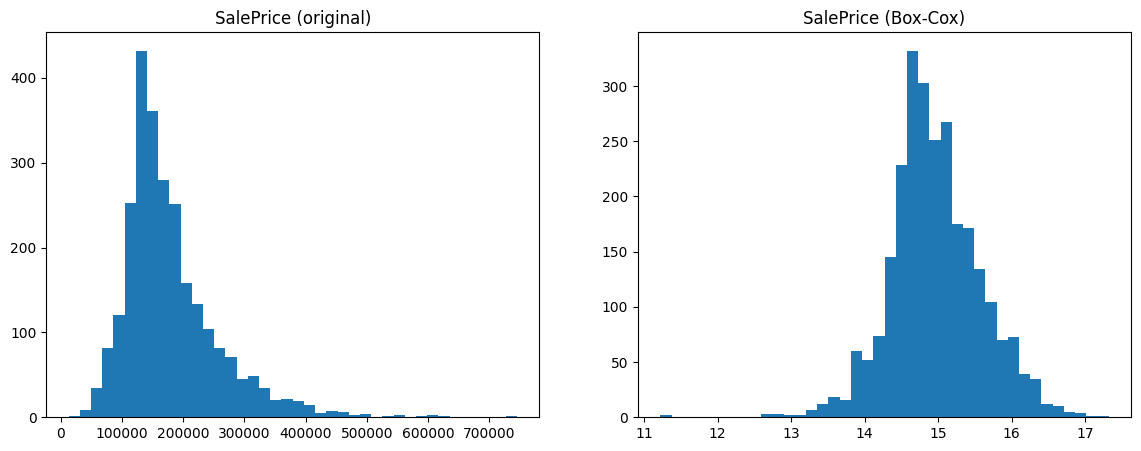

In [24]:
# Box-Cox: does it make SalePrice more bell-shaped?
fitted_data, fitted_lambda = stats.boxcox(house_df_all['SalePrice'])
print(f"Lambda: {fitted_lambda}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(house_df_all['SalePrice'], bins=40)
axes[0].set_title('SalePrice (original)')
axes[1].hist(fitted_data, bins=40)
axes[1].set_title('SalePrice (Box-Cox)')
plt.show()

#### Feature Selection

In [25]:
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import f_regression

In [26]:
# Target
y = house_df_all['SalePrice']

# Number features (drop the target)
X_num = house_df_all[num_columns].drop(columns=['SalePrice'])

# Text features, one-hot encoded
X_text = pd.get_dummies(house_df_all[obj_columns], drop_first=True, dtype=int)

# Everything together, for the starting score
X = pd.concat([X_num, X_text], axis=1)

print(X_num.shape, X_text.shape, X.shape)

(2611, 36) (2611, 237) (2611, 273)


In [27]:
# Repeat CV - Linear Regression with ALL features (numbers + encoded text)
n = 500
results = np.zeros(n)

for i in range(n):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25)
    model = LinearRegression()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    results[i] = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"Repeat CV RMSE (all features): {results.mean().round(2)}")
print(f"Number of features: {X.shape[1]}")

Repeat CV RMSE (all features): 34259.62
Number of features: 273


#### Feature Selection - Correlation (number features)

In [28]:
# Score each number feature by how strongly it moves with SalePrice
corrs = house_df_all[num_columns].corr()['SalePrice'].abs().sort_values(ascending=False)

# Keep features above 0.5 (and drop SalePrice itself, which scores 1)
keep_num = corrs[(corrs > 0.5) & (corrs < 1)]
selected_num = keep_num.index.tolist()
selected_num

['Overall Qual',
 'Gr Liv Area',
 'Garage Cars',
 'Garage Area',
 'Total Bsmt SF',
 '1st Flr SF',
 'Year Built',
 'Full Bath',
 'Year Remod/Add',
 'Garage Yr Blt',
 'Mas Vnr Area']

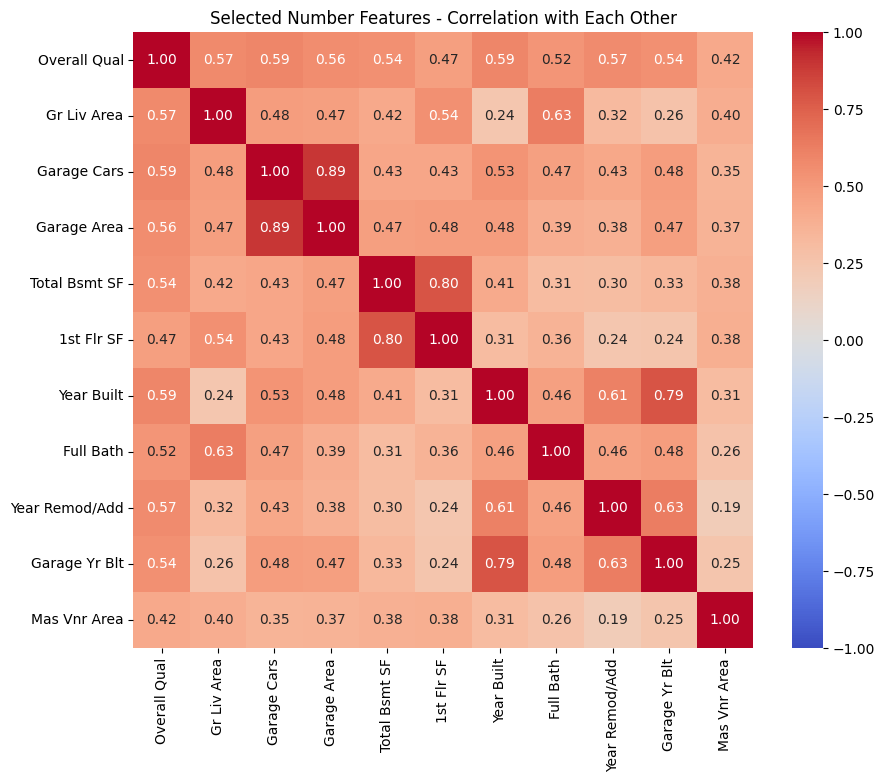

In [29]:
# Check if the selected number features overlap each other
plt.figure(figsize=(10, 8))
sns.heatmap(house_df_all[selected_num].corr(), annot=True, fmt='.2f',
            cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Selected Number Features - Correlation with Each Other')
plt.show()

In [30]:
# Drop the lower-scoring feature from each overlapping pair
X_corr = house_df_all[selected_num].drop(columns=['Garage Area'])
X_corr.columns

Index(['Overall Qual', 'Gr Liv Area', 'Garage Cars', 'Total Bsmt SF',
       '1st Flr SF', 'Year Built', 'Full Bath', 'Year Remod/Add',
       'Garage Yr Blt', 'Mas Vnr Area'],
      dtype='object')

#### Feature Selection - ANOVA (text features)

<Axes: >

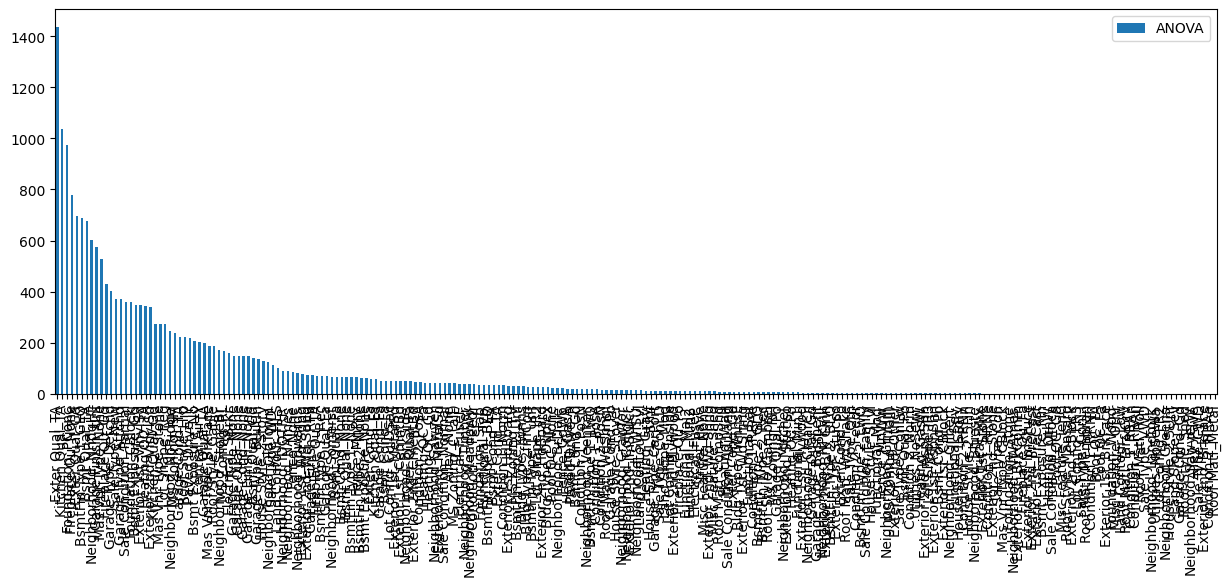

In [31]:
# Score every encoded text column with an ANOVA F-value
fvalue_selector = SelectKBest(f_regression, k='all')
fvalue_selector.fit_transform(X_text, y)

# Plot results, biggest first
anova_results = pd.DataFrame({'ANOVA': fvalue_selector.scores_}, index=X_text.columns)
anova_results.sort_values(by='ANOVA', ascending=False).plot(kind='bar', figsize=(15, 5))

In [32]:
# Keep columns with F-value greater than 10
anova = anova_results.sort_values(by='ANOVA', ascending=False)
keep = anova['ANOVA'][anova['ANOVA'] > 10]
print(keep.index.size)
keep

135


,ANOVA
Exter Qual_TA,1434.018846
Kitchen Qual_TA,1036.375990
Foundation_PConc,973.304756
Fireplace Qu_None,778.896433
Exter Qual_Gd,697.366775
...,...
Electrical_FuseP,10.516742
Street_Pave,10.506297
Misc Feature_None,10.419160
Exterior 2nd_Wd Shng,10.358631


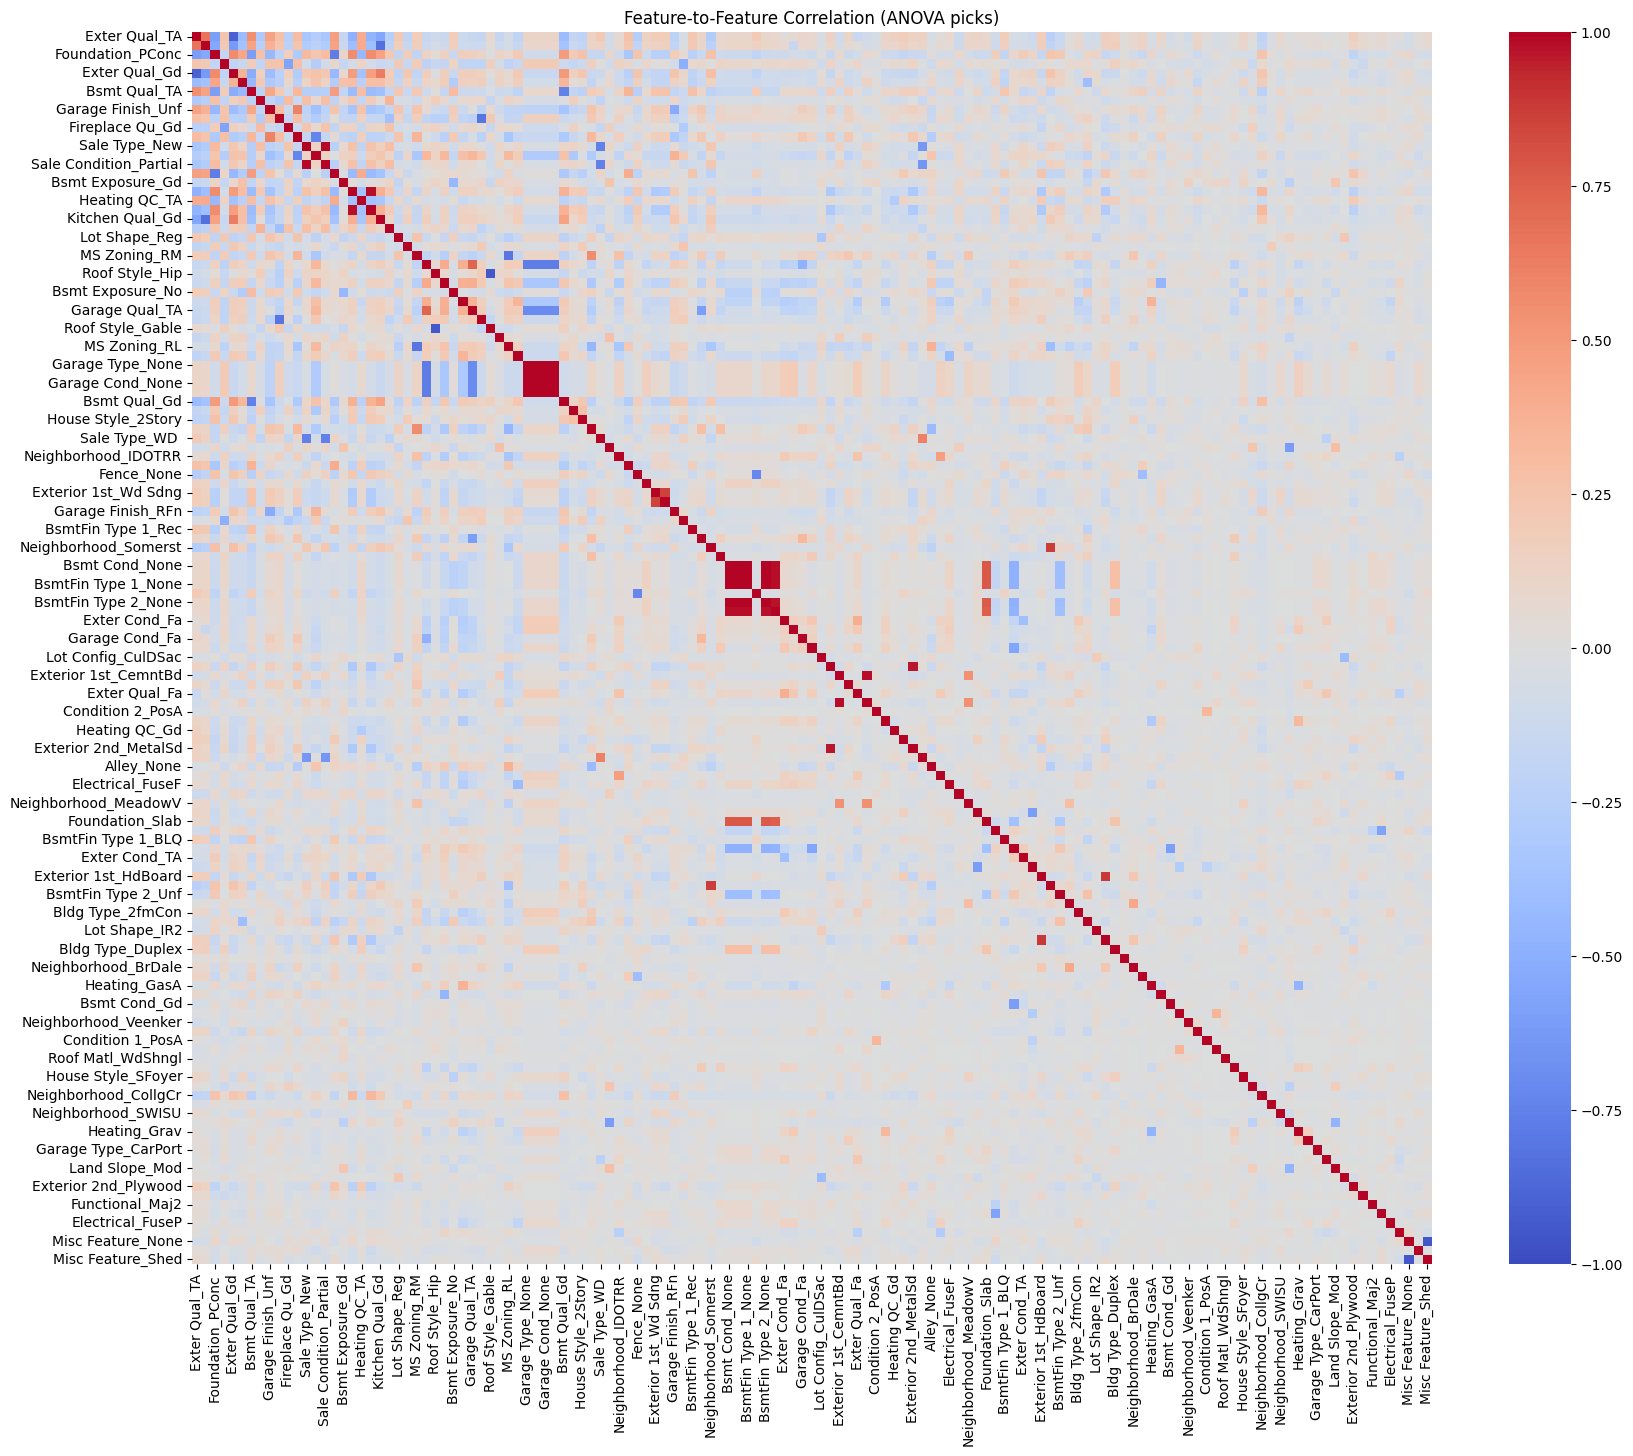

In [33]:
# Are the kept features correlated with each other?
X_anova = X_text[keep.index]
plt.figure(figsize=(20, 16))
sns.heatmap(X_anova.corr(), annot=False, cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Feature-to-Feature Correlation (ANOVA picks)')
plt.show()

In [34]:
# Find columns that are exact copies of another column
# .T flips rows and columns, so duplicated() can compare columns
dupes = X_anova.columns[X_anova.T.duplicated()].tolist()
dupes

['Garage Cond_None',
 'Garage Finish_None',
 'Bsmt Qual_None',
 'BsmtFin Type 1_None']

In [35]:
# Drop exact duplicate columns (they repeat another column word for word)
drop_these = dupes
X_anova = X_anova.drop(columns=drop_these)
X_anova.shape

(2611, 131)

## Processing

In [36]:
### combine the two groups

# Join ANOVA text picks + correlation number picks
X2 = pd.concat([X_anova, X_corr], axis=1)
(X_corr.shape, X_anova.shape, X2.shape)

((2611, 10), (2611, 131), (2611, 141))

In [37]:
# Does any number feature repeat a text feature?
# For each number feature, find the text column it matches most closely
cross = X2.corr().loc[X_corr.columns, X_anova.columns].abs()
pd.DataFrame({'Closest text column': cross.idxmax(axis=1),
              'Correlation': cross.max(axis=1).round(2)}).sort_values('Correlation', ascending=False)

,Closest text column,Correlation
Mas Vnr Area,Mas Vnr Type_None,0.70
Overall Qual,Exter Qual_TA,0.64
Garage Yr Blt,Foundation_PConc,0.64
Year Built,Foundation_PConc,0.64
Year Remod/Add,Kitchen Qual_TA,0.59
Garage Cars,Garage Type_None,0.56
Gr Liv Area,House Style_2Story,0.48
Full Bath,Foundation_PConc,0.47
Total Bsmt SF,Bsmt Cond_None,0.41
1st Flr SF,Garage Type_Attchd,0.37


In [38]:
# Drop cross-group overlaps (fill in from the table above)
drop_cross = []
X2 = X2.drop(columns=drop_cross)
X2.shape

(2611, 141)

### Fit & Assess model- Using linear Regression + Box-Cox

In [39]:
# break data into training and testing sets
X = X2
y = house_df_all['SalePrice']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=4)

In [40]:
# Fit a linear model using sklearn
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

(model.intercept_, model.coef_)

(np.float64(-567939.386404401),
 array([-1.81384973e+04, -2.90437988e+04,  3.73004987e+03,  3.54684974e+02,
        -1.70688288e+04,  3.40350969e+03, -1.91856052e+04,  2.06243019e+04,
        -1.82289601e+03,  1.52569807e+04,  3.41830635e+03,  1.11030665e+04,
        -1.27441122e+04,  1.33940283e+04,  2.79292853e+04,  2.41480910e+03,
         1.70780202e+04, -1.12695288e+04, -4.13807637e+03,  7.88113068e+03,
        -2.63683090e+04,  1.27482252e+04, -7.94615400e+02,  3.98680846e+04,
        -9.27915276e+03,  2.10701918e+03,  5.19695384e+03, -1.56363580e+03,
        -4.70289624e+03,  1.44220320e+03, -7.08708798e+03,  7.10401891e+03,
         2.92708381e+03,  3.31654209e+04,  2.02369857e+03, -4.59268949e+02,
         3.04084640e+04, -1.91404040e+04, -1.97330168e+04,  1.32584676e+04,
        -6.89310498e+02,  5.77013520e+02,  1.28713863e+03,  6.53792867e+03,
         7.16963193e+03, -1.67352368e+03, -1.08731665e+03, -8.20757887e+03,
        -4.23667556e+03,  2.21671029e+03, -5.60120933e+0

[(270000, np.float64(306799.9882613678)),
 (255000, np.float64(228941.66951975937)),
 (149900, np.float64(153014.04756481305)),
 (260000, np.float64(282586.96993153717)),
 (143750, np.float64(125831.92131835385)),
 (115000, np.float64(99349.96938120318)),
 (140000, np.float64(134618.2516880416)),
 (213750, np.float64(210352.49549849937)),
 (173000, np.float64(176343.90094785474)),
 (124500, np.float64(116931.69742934394))]

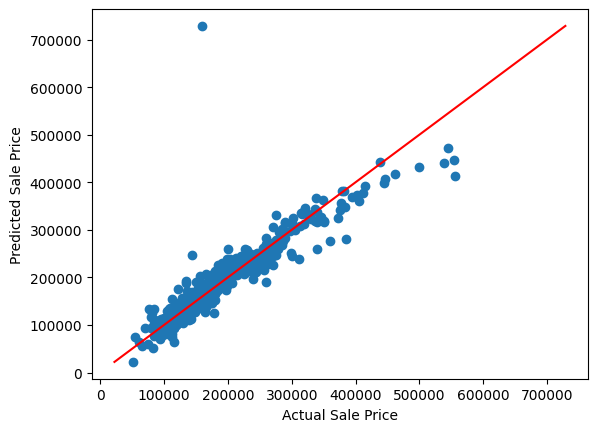

In [41]:
# See how well the model does compare to the test data

plt.scatter(y_test, y_pred)
plt.plot([min(y_pred), max(y_pred)], [min(y_pred), max(y_pred)], c='red')
plt.xlabel('Actual Sale Price')
plt.ylabel('Predicted Sale Price');

list(zip(y_test, y_pred))[:10]

In [42]:
# RMS on test data
rmse = mean_squared_error(y_test, y_pred)**0.5
print(f"RMSE: {rmse} ")

#RMSE- shows the amount the model was wrong

RMSE: 34032.02558323854 


In [43]:
# Use cross validation to assess model performance
results = cross_val_score(model, X, y, scoring='neg_root_mean_squared_error', cv=10)
cv_rmse = abs(results.mean())
print(f"CV RMSE: {cv_rmse}")



CV RMSE: 27594.84843428228


In [44]:
# Repeat CV - Linear Regression with SELECTED features (same method as the all-features score)
results = np.zeros(n)

for i in range(n):
    X_train, X_test, y_train, y_test = train_test_split(X2, y, test_size=0.25)
    model = LinearRegression()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    results[i] = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"Repeat CV RMSE (selected features): {results.mean().round(2)}")
print(f"Number of features: {X2.shape[1]}")

Repeat CV RMSE (selected features): 29084.89
Number of features: 141


In [45]:
# Repeat CV - Linear Regression + Box-Cox, selected features
results = np.zeros(n)

for i in range(n):
    X_train, X_test, y_train, y_test = train_test_split(X2, y, test_size=0.25)

    # 1. Box-Cox the training prices only
    fitted_data, fitted_lambda = stats.boxcox(y_train)

    # 2. Fit on the transformed prices
    model = LinearRegression()
    model.fit(X_train, fitted_data)
    y_pred = model.predict(X_test)

    # 3. Turn predictions back into dollars
    real_y_pred = special.inv_boxcox(y_pred, fitted_lambda)

    # 4. Score in dollars
    results[i] = np.sqrt(mean_squared_error(y_test, real_y_pred))

print(f"Repeat CV RMSE (Box-Cox, selected features): {results.mean().round(2)}")
print(f"Number of features: {X2.shape[1]}")

Repeat CV RMSE (Box-Cox, selected features): 34571.76
Number of features: 141


In [46]:
# Re-fit with Box-Cox on the fixed split, for the residual plots
X_train, X_test, y_train, y_test = train_test_split(X2, y, test_size=0.2, random_state=4)
fitted_data, fitted_lambda = stats.boxcox(y_train)

model = LinearRegression()
model.fit(X_train, fitted_data)
real_y_pred = special.inv_boxcox(model.predict(X_test), fitted_lambda)

# Residual plots below use y_pred, so point it at the dollar predictions
y_pred = real_y_pred

rmse = mean_squared_error(y_test, y_pred)**0.5
print(f"RMSE (Box-Cox, fixed split): {rmse}")

RMSE (Box-Cox, fixed split): 56938.558990123


## Residual Analysis

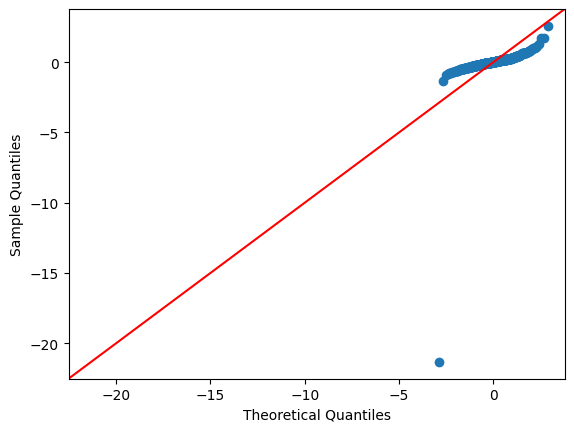

In [47]:
# QQ Plot - Checks if residuals(misses)are normally distributed (bell-shaped)
# res= real price- guess. Positive= guessed to low. Negative= guesses to high
# fit=True, converts model misses from dollars into standard units
# line="45" draws a line where "should be" = "actually is
# Read it: dots on red line= normal. Ends curving away= not normal


res = y_test - y_pred
sm.qqplot(res, fit=True, line="45") ;

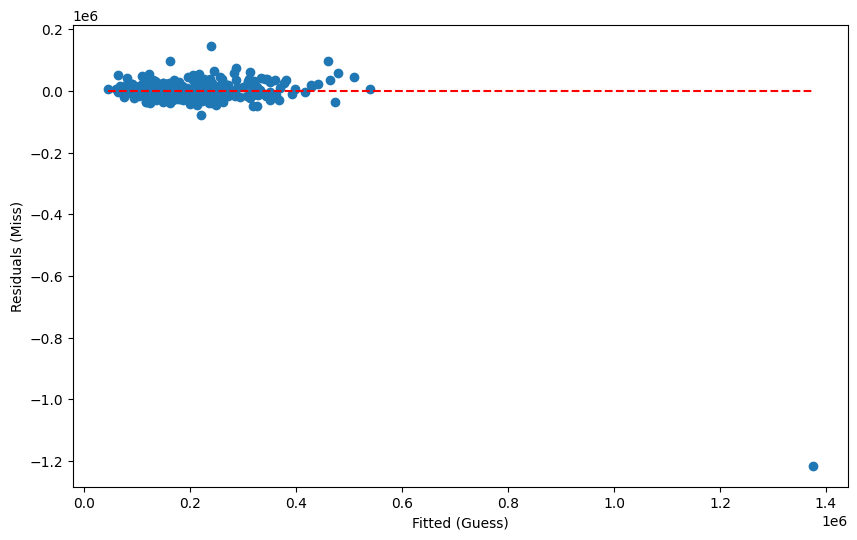

In [48]:
# Residuals vs Fitted (Predicted) Values - Constant variance

plt.figure(figsize = (10,6))
plt.scatter(y_pred, res)
plt.xlabel("Fitted (Guess)")
plt.ylabel("Residuals (Miss)")
plt.hlines(0, min(y_pred), max(y_pred), colors = 'red', linestyles = 'dashed') ;

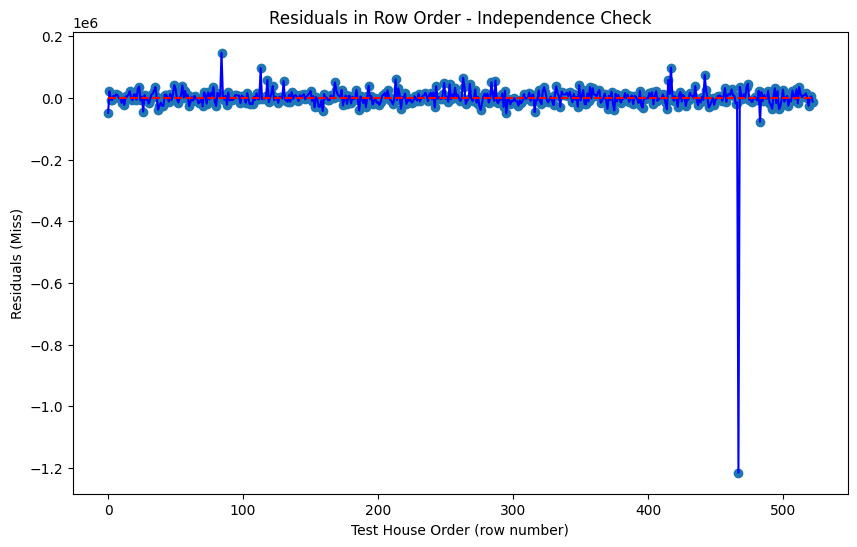

In [49]:
# Residuals vs Time - checks indepedence
plt.figure(figsize = (10,6))
plt.scatter(range(len(res)), res)
plt.plot(range(len(res)), res, 'b')
plt.xlabel("Test House Order (row number)")
plt.ylabel("Residuals (Miss)")
plt.title("Residuals in Row Order - Independence Check")
plt.hlines(0, min(range(len(res))), max(range(len(res))), colors = 'red', linestyles = 'dashed') ;